# 03 — Model Experiment 2 (with duration) (Thử nghiệm Mô hình)

> Bank Marketing — so sánh baseline, nhiều algorithm, tuning và chốt 1 model bàn giao cho `src/models/train.py`.
>
> Notebook chạy được **Colab** lẫn **local** (thứ tự import/mount giữ đồng nhất với `01_eda.ipynb` và `02_preprocessing.ipynb`).

Lộ trình 6 bước (đã chỉnh riêng cho dự án này):

| Bước | Tên | Mục tiêu chính | Output |
| --- | --- | --- | --- |
| **1** | **Load Data & Preprocessing** | Có `X_train/y_train`, `X_val/y_val`, `X_test/y_test` + 1 `preprocessor` duy nhất | `X_*`, `y_*`, `preprocessor`, `num_cols`, `cat_cols` |
| 2 | Baseline Model | Cột mốc `Dummy (most_frequent / stratified)` + `LogisticRegression` | `baseline_df` + report/CM |
| 3 | Thử nghiệm nhiều Algorithm | So nhanh các họ model với cùng 1 pipeline | `results_df` |
| 4 | Đánh giá & So sánh | Bảng tổng + 3 bộ biểu đồ | `results_all` + hình |
| 5 | Tinh chỉnh Tham số | Tối ưu Top-2 (`RandomizedSearchCV` / `Optuna`) | `tuned_results` + Δ |
| 6 | Phân tích & Kết luận | Chốt 1 model, importance, hold-out test, bàn giao | `BEST_NAME`, `BEST_PARAMS` |

> **Phạm vi file hiện tại:** mới ghi **Bước 1** để bạn kiểm tra. Các Bước 2→6 sẽ ghi tiếp sau khi Bước 1 được duyệt — không trộn code để dễ review từng phần.

---

### Quy ước chung cho cả notebook

- `data/processed/train_2.csv` (31 647) + `val_2.csv` (6 782) + `test_2.csv` (6 782) đã chia **70/15/15 stratified** — là nguồn chính. Nếu chưa có thì fallback đọc `data/interim/clean_2.csv` (45 211) và tự split trong notebook.
- `duration` được **giữ** từ `02_preprocessing` / `src/data/preprocessing_2.py` (leakage — điểm cao ảo, dùng để so sánh upper bound) — model dùng feature biết cả **trước và sau khi gọi**.
- `y` là `0/1` (`88:12`), `pdays` có `~81% NaN` sau khi `-1 → NaN` và đã tách `contacted_before`.
- `preprocessor = build_preprocessor()` từ `src/data/preprocessing_2.py` — `median` cho `pdays` + `OneHot(handle_unknown='ignore')` cho 9 cột categorical. **Tuyệt đối không `fit` gì ngoài `Pipeline`**.


## 0. Setup môi trường

> Giữ cùng thứ tự import với `01_eda.ipynb` / `02_preprocessing.ipynb` để dễ đối chiếu.
> Trên Colab nếu cần mount Drive thì bỏ comment 2 dòng `drive.mount` ở cell code.


In [2]:
# ============================================================
# 03_model_experiment_2 - Buoc 0: Setup moi truong (Colab + local)
# ============================================================
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    display = print  # fallback khi chay .py thuan

# --- hien thi ---
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.4f}'.format)

print(f"pandas {pd.__version__} | numpy {np.__version__}")
try:
    import sklearn
    print(f"scikit-learn {sklearn.__version__}")
except ImportError:
    print("scikit-learn chua cai — can pip install scikit-learn")

# --- Mount Google Drive (chi can tren Colab, local thi bo qua) ---
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass  # local: khong co google.colab -> bo qua

# --- Tim PROJECT_ROOT tu dong: Colab truoc, local sau ---
# Thu tu uu tien: Colab Drive -> chay tu notebooks/ -> chay tu my_ds_project/ -> tuyet doi Windows
CANDIDATE_ROOTS = [
    Path("/content/drive/MyDrive/my_ds_project"),          # Colab
    Path(".."),                                              # chay tu notebooks/
    Path("."),                                               # chay tu my_ds_project/
    Path("my_ds_project"),                                  # chay tu repo root tren Colab
    Path.cwd(),
    Path.cwd() / "my_ds_project",
    Path("C:/Users/Admin/Desktop/Banking Dataset - Marketing Targets/my_ds_project"),  # local tuyet doi (Windows)
]
# Chuan hoa va tim root hop le (co data/processed hoac data/interim)
PROJECT_ROOT = None
for r in CANDIDATE_ROOTS:
    try:
        rp = r.resolve()
    except Exception:
        rp = r
    if (rp / "data" / "processed" / "train_2.csv").exists() or (rp / "data" / "interim" / "clean_2.csv").exists() or (rp / "notebooks").exists():
        PROJECT_ROOT = rp
        break
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path("..").resolve() if Path("../data").exists() else Path.cwd()

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_INTERIM   = PROJECT_ROOT / "data" / "interim"
SRC_DIR        = PROJECT_ROOT / "src"

# Bao dam import duoc src.data.preprocessing du chay tu notebooks/
for p in [str(PROJECT_ROOT), str(PROJECT_ROOT / "src"), str(PROJECT_ROOT.parent)]:
    if p not in sys.path:
        sys.path.insert(0, p)

print(f"PROJECT_ROOT  = {PROJECT_ROOT}  (exists={PROJECT_ROOT.exists()})")
print(f"DATA_PROCESSED= {DATA_PROCESSED}  (exists={DATA_PROCESSED.exists()})")
print(f"DATA_INTERIM  = {DATA_INTERIM}  (exists={DATA_INTERIM.exists()})")
print(f"SRC_DIR       = {SRC_DIR}  (exists={SRC_DIR.exists()})")
print()

# --- Hang so dung chung ---
TARGET = "y"
print(f"TARGET={TARGET}")
print("San sang cho Buoc 1: Load Data & Preprocessing")


Mounted at /content/drive
PROJECT_ROOT  = /content/drive/MyDrive/my_ds_project  (exists=True)
DATA_PROCESSED= /content/drive/MyDrive/my_ds_project/data/processed  (exists=True)
DATA_INTERIM  = /content/drive/MyDrive/my_ds_project/data/interim  (exists=True)
SRC_DIR       = /content/drive/MyDrive/my_ds_project/src  (exists=True)

TARGET=y
San sang cho Buoc 1: Load Data & Preprocessing


## 1. Load Data & Preprocessing

> **Mục tiêu:** có `X_train/y_train`, `X_val/y_val`, `X_test/y_test` và **1 `preprocessor` duy nhất** dùng cho cả notebook.
>
> **Thứ tự bắt buộc trong cell code dưới:**
> 1. Thử load `data/processed/train_2.csv` (31 647) + `val_2.csv` (6 782) + `test_2.csv` (6 782) đã chia **70/15/15 stratified** — đây là nguồn chính.
> 2. Nếu **chưa có** (ví dụ mới clone repo, chưa chạy split) → fallback đọc `data/interim/clean_2.csv` (45 211) và **tự split trong notebook** với `train_test_split(..., stratify=y, random_state=42)` theo đúng tỉ lệ 70/15/15.
> 3. Kiểm tra nhanh: `duration` đã **GIU**, `contacted_before` đã có, `y` là `0/1` (`88:12`), `pdays` có `~81% NaN`.
> 4. Tách `FEATURE_COLS = [c for c in df.columns if c != 'y']`.
> 5. Dựng `preprocessor = build_preprocessor()` từ `src/data/preprocessing_2.py` — `median` cho `pdays` + `OneHot(handle_unknown='ignore')` cho 9 cột categorical. **Tuyệt đối không `fit` gì ngoài `Pipeline`** (mọi `fit` sẽ nằm trong `Pipeline([('pre', preprocessor), ('clf', ...)])` ở Bước 2+).
>
> **Lưu ở đâu?** Chỉ trong RAM (`X_*`, `y_*`, `preprocessor`). **Không ghi ra file** ở bước này.
>
> **Output của bước:** `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`, `preprocessor`, `num_cols`, `cat_cols` (+ `FEATURE_COLS`, `TARGET`, `DATA_SOURCE` để debug).


In [3]:
# ============================================================
# Buoc 1: Load Data & Preprocessing
# - Uu tien data/processed (70/15/15 stratified san)
# - Fallback data/interim/clean_2.csv -> tu split neu chua co processed
# - Dung build_preprocessor() tu src/data/preprocessing_2.py
# - Tuyet doi KHONG fit gi ngoai Pipeline
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print

# --- 1a. Dinh vi file ---
TRAIN_P = DATA_PROCESSED / "train_2.csv"
VAL_P   = DATA_PROCESSED / "val_2.csv"
TEST_P  = DATA_PROCESSED / "test_2.csv"
CLEAN_P = DATA_INTERIM / "clean_2.csv"
# Tuong thich nguoc: notebook cu ghi train_clean_2.csv
CLEAN_ALT = DATA_INTERIM / "train_clean_2.csv"

print("=== 1a. Dinh vi file ===")
for label, p in [("train_2.csv (processed)", TRAIN_P), ("val_2.csv (processed)", VAL_P), ("test_2.csv (processed)", TEST_P), ("clean_2.csv (interim)", CLEAN_P), ("train_clean_2.csv (interim alt)", CLEAN_ALT)]:
    print(f"  {label:28s}: {p}  exists={p.exists()}")
print()

# --- 1b. Load chinh: data/processed neu du 3 file ---
DATA_SOURCE = None
if TRAIN_P.exists() and VAL_P.exists() and TEST_P.exists():
    print("=== 1b. Load tu data/processed (70/15/15 stratified san) ===")
    train_df = pd.read_csv(TRAIN_P)
    val_df   = pd.read_csv(VAL_P)
    test_df  = pd.read_csv(TEST_P)
    DATA_SOURCE = "processed (70/15/15)"
    print(f"  train_df: {train_df.shape} | val_df: {val_df.shape} | test_df: {test_df.shape}")
else:
    print("=== 1b. Fallback: data/processed chua du -> doc data/interim/clean_2.csv va tu split ===")
    clean_path = CLEAN_P if CLEAN_P.exists() else CLEAN_ALT
    assert clean_path.exists(), f"Khong tim thay processed (3 file) va cung khong thay {CLEAN_P} / {CLEAN_ALT} — chay 02_preprocessing hoac src/data/preprocessing_2.py truoc"
    print(f"  Doc tu: {clean_path}")
    df_clean = pd.read_csv(clean_path)
    print(f"  df_clean shape: {df_clean.shape} | columns: {list(df_clean.columns)}")
    from sklearn.model_selection import train_test_split
    assert TARGET in df_clean.columns, f"Thieu cot TARGET='{TARGET}' trong clean_2.csv"
    X_full = df_clean.drop(columns=[TARGET])
    y_full = df_clean[TARGET].astype(int)
    X_train_tmp, X_rem, y_train_tmp, y_rem = train_test_split(
        X_full, y_full, test_size=0.30, random_state=42, stratify=y_full
    )
    X_val_tmp, X_test_tmp, y_val_tmp, y_test_tmp = train_test_split(
        X_rem, y_rem, test_size=0.50, random_state=42, stratify=y_rem
    )
    train_df = pd.concat([X_train_tmp, y_train_tmp], axis=1)
    val_df   = pd.concat([X_val_tmp,   y_val_tmp], axis=1)
    test_df  = pd.concat([X_test_tmp,  y_test_tmp], axis=1)
    DATA_SOURCE = f"interim fallback ({clean_path.name} -> 70/15/15 stratified)"
    print(f"  Tu split -> train_df: {train_df.shape} | val_df: {val_df.shape} | test_df: {test_df.shape}")
print(f"DATA_SOURCE = {DATA_SOURCE}")
print()

# --- 1c. Kiem tra nhanh schema & gia tri dac thu ---
print("=== 1c. Kiem tra nhanh (duration/contacted_before/y/pdays) ===")
for name, dframe in [("train", train_df), ("val", val_df), ("test", test_df)]:
    cols = list(dframe.columns)
    has_duration = "duration" in cols
    has_contacted = "contacted_before" in cols
    has_y = TARGET in cols
    y_vals = sorted(dframe[TARGET].dropna().unique().tolist()) if has_y else []
    y_mean = dframe[TARGET].mean() if has_y else float("nan")
    n_yes  = (dframe[TARGET] == 1).sum() if has_y else 0
    n_no   = (dframe[TARGET] == 0).sum() if has_y else 0
    pdays_nan = dframe["pdays"].isna().sum() if "pdays" in cols else -1
    pdays_nan_pct = pdays_nan / len(dframe) * 100 if "pdays" in cols else float("nan")
    print(f"  [{name:5s}] shape={str(dframe.shape):14s} | duration={'CON' if has_duration else 'drop OK':7s} | contacted_before={'co' if has_contacted else 'THIEU':5s} | y={y_vals} {(n_no, n_yes)} yes={y_mean*100:.1f}% | pdays NaN={pdays_nan} ({pdays_nan_pct:.1f}%)")
print()
print("--- Preview train_df.head(3) ---")
display(train_df.head(3))
print(f"Columns train: {list(train_df.columns)}")
print()

# --- 1d. Assert gac cong ---
print("=== 1d. Assert gac cong ===")
total = len(train_df) + len(val_df) + len(test_df)
print(f"  Tong dong 3 file: {total} (ky vong 45211 neu du processed)")
assert TARGET in train_df.columns and TARGET in val_df.columns and TARGET in test_df.columns, f"Thieu cot '{TARGET}' o 1 trong 3 file"
assert "duration" in train_df.columns, "Thieu cot 'duration' trong train_df — phai GIU (leakage, diem cao ao)"
assert "duration" in val_df.columns and "duration" in test_df.columns, "Thieu 'duration' o val/test — phai GIU dong bo"
assert "contacted_before" in train_df.columns, "Thieu 'contacted_before' — phai co tu Buoc 3 (pdays -1 -> NaN)"
assert set(train_df[TARGET].dropna().unique()) <= {0, 1}, f"y train phai 0/1, got {sorted(train_df[TARGET].unique())}"
assert set(val_df[TARGET].dropna().unique()) <= {0, 1}, f"y val phai 0/1"
assert set(test_df[TARGET].dropna().unique()) <= {0, 1}, f"y test phai 0/1"
for name, dframe in [("train", train_df), ("val", val_df), ("test", test_df)]:
    pct = dframe["pdays"].isna().mean() * 100
    assert 70 <= pct <= 90, f"{name} pdays NaN {pct:.1f}% nam ngoai 70-90% — kiem tra lai Buoc 3"
assert train_df[TARGET].isna().sum() == 0 and val_df[TARGET].isna().sum() == 0 and test_df[TARGET].isna().sum() == 0, "y co NaN"
if DATA_SOURCE.startswith("processed"):
    assert train_df.shape[0] == 31647, f"train phai 31647, got {train_df.shape[0]}"
    assert val_df.shape[0]   == 6782,  f"val phai 6782, got {val_df.shape[0]}"
    assert test_df.shape[0]  == 6782,  f"test phai 6782, got {test_df.shape[0]}"
print("  Tat ca assert: PASS (duration da GIU, contacted_before co, y 0/1, pdays ~81% NaN, y khong NaN)")
print()

# --- 1e. Tach FEATURE_COLS / TARGET va tao X_*/y_* ---
print("=== 1e. Tach FEATURE_COLS & tao X_*/y_* ===")
FEATURE_COLS = [c for c in train_df.columns if c != TARGET]
print(f"  FEATURE_COLS ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"  TARGET = '{TARGET}'")
print()
X_train = train_df[FEATURE_COLS].copy()
y_train = train_df[TARGET].astype(int).copy()
X_val   = val_df[FEATURE_COLS].copy()
y_val   = val_df[TARGET].astype(int).copy()
X_test  = test_df[FEATURE_COLS].copy()
y_test  = test_df[TARGET].astype(int).copy()
for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    yes = (y == 1).sum()
    no  = (y == 0).sum()
    print(f"  {name:5s}: X={str(X.shape):14s} y={str(y.shape):10s} | y 0/1 = {no}/{yes} ({y.mean()*100:.2f}% yes) | X cols={X.shape[1]}")
print()
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns), "Cot X_train/val/test lech nhau"
assert list(X_train.columns) == FEATURE_COLS, "FEATURE_COLS khong khop X_train.columns"
print("  Assert cot dong nhat 3 tap: PASS")
print()

# --- 1f. Dung preprocessor duy nhat tu src/data/preprocessing_2.py ---
print("=== 1f. Dung preprocessor duy nhat (build_preprocessor()) ===")
try:
    from src.data.preprocessing_2 import build_preprocessor
    print("  from src.data.preprocessing_2 import build_preprocessor : OK")
except ImportError as e1:
    try:
        from preprocessing import build_preprocessor
        print("  from preprocessing import build_preprocessor : OK (fallback)")
    except ImportError as e2:
        raise ImportError(
            f"Khong import duoc build_preprocessor: {e1} / {e2}. "
            f"PROJECT_ROOT={PROJECT_ROOT}, sys.path[0:3]={sys.path[0:3]}"
        ) from e1
preprocessor, num_cols, cat_cols = build_preprocessor()
print(f"  num_cols ({len(num_cols)}): {num_cols}")
print(f"  cat_cols ({len(cat_cols)}): {cat_cols}")
print(f"  preprocessor: {preprocessor}")
print()
print("  Luu y QUAN TRONG:")
print("    - preprocessor nay la 1 ColumnTransformer duy nhat dung cho CA notebook.")
print("    - Numeric: SimpleImputer(strategy='median') cho pdays (NaN ~81%).")
print("    - Categorical: OneHotEncoder(handle_unknown='ignore', sparse_output=False) cho 9 cot.")
print("    - TUYET DOI KHONG fit gi ngoai Pipeline:")
print("        pipe = Pipeline([('pre', preprocessor), ('clf', LogisticRegression(...))])")
print("        pipe.fit(X_train, y_train)  # fit ca preprocessor + clf trong 1 lan")
print()

# --- 1g. Kiem tra preprocessor chua fit va khop cot ---
print("=== 1g. Kiem tra preprocessor (chua fit) ===")
from sklearn.compose import ColumnTransformer
assert isinstance(preprocessor, ColumnTransformer), f"preprocessor phai la ColumnTransformer, got {type(preprocessor)}"
missing_num = set(num_cols) - set(FEATURE_COLS)
missing_cat = set(cat_cols) - set(FEATURE_COLS)
assert not missing_num, f"num_cols co cot khong nam trong FEATURE_COLS: {missing_num}"
assert not missing_cat, f"cat_cols co cot khong nam trong FEATURE_COLS: {missing_cat}"
assert "duration" in num_cols, "preprocessor phai GIU 'duration' (leakage — diem cao ao, so sánh upper bound)"
assert "contacted_before" in num_cols, "Thieu 'contacted_before' trong num_cols"
assert "pdays" in num_cols, "Thieu 'pdays' trong num_cols (cot co NaN can median impute)"
print(f"  ColumnTransformer: OK | num {len(num_cols)} + cat {len(cat_cols)} = {len(num_cols)+len(cat_cols)} cot truyen vao transformer")
print(f"  FEATURE_COLS {len(FEATURE_COLS)} cot -> transformer nhan {len(num_cols)+len(cat_cols)} cot (khop, con lai drop='drop')")
print(f"  keep duration=True -> co 'duration' trong num_cols: PASS")
print()

# --- 1h. Tong ket output Buoc 1 ---
print("=== 1h. Tong ket Buoc 1 ===")
print(f"  DATA_SOURCE : {DATA_SOURCE}")
print(f"  PROJECT_ROOT: {PROJECT_ROOT}")
print(f"  FEATURE_COLS ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"  TARGET      : {TARGET}")
print(f"  X_train     : {X_train.shape} | y_train: {y_train.shape}  yes={y_train.mean()*100:.2f}%")
print(f"  X_val       : {X_val.shape}   | y_val  : {y_val.shape}    yes={y_val.mean()*100:.2f}%")
print(f"  X_test      : {X_test.shape}  | y_test : {y_test.shape}   yes={y_test.mean()*100:.2f}%  (chua dung toi khi Buoc 6c)")
print(f"  preprocessor: ColumnTransformer(num={num_cols}, cat={cat_cols})")
print(f"  num_cols    : {num_cols}")
print(f"  cat_cols    : {cat_cols}")
print()
print("San sang cho Buoc 2: Baseline Model (Dummy + LogisticRegression trong Pipeline).")
print("Ghi chu: X_test/y_test chi duoc predict DUY NHAT 1 lan o Buoc 6c (hold-out test).")


=== 1a. Dinh vi file ===
  train_2.csv (processed)     : /content/drive/MyDrive/my_ds_project/data/processed/train_2.csv  exists=True
  val_2.csv (processed)       : /content/drive/MyDrive/my_ds_project/data/processed/val_2.csv  exists=True
  test_2.csv (processed)      : /content/drive/MyDrive/my_ds_project/data/processed/test_2.csv  exists=True
  clean_2.csv (interim)       : /content/drive/MyDrive/my_ds_project/data/interim/clean_2.csv  exists=True
  train_clean_2.csv (interim alt): /content/drive/MyDrive/my_ds_project/data/interim/train_clean_2.csv  exists=False

=== 1b. Load tu data/processed (70/15/15 stratified san) ===
  train_df: (31647, 18) | val_df: (6782, 18) | test_df: (6782, 18)
DATA_SOURCE = processed (70/15/15)

=== 1c. Kiem tra nhanh (duration/contacted_before/y/pdays) ===
  [train] shape=(31647, 18)    | duration=CON     | contacted_before=co    | y=[0, 1] (np.int64(27945), np.int64(3702)) yes=11.7% | pdays NaN=25912 (81.9%)
  [val  ] shape=(6782, 18)     | duration=C

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,contacted_before
0,31,services,married,secondary,no,1,yes,no,cellular,9,jul,82,1,NaN,0,unknown,0,0
1,35,services,married,secondary,no,195,yes,no,cellular,17,apr,203,1,NaN,0,unknown,0,0
2,24,blue-collar,single,secondary,no,77,yes,no,unknown,16,may,236,2,NaN,0,unknown,0,0


Columns train: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y', 'contacted_before']

=== 1d. Assert gac cong ===
  Tong dong 3 file: 45211 (ky vong 45211 neu du processed)
  Tat ca assert: PASS (duration da GIU, contacted_before co, y 0/1, pdays ~81% NaN, y khong NaN)

=== 1e. Tach FEATURE_COLS & tao X_*/y_* ===
  FEATURE_COLS (17): ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'contacted_before']
  TARGET = 'y'

  train: X=(31647, 17)    y=(31647,)   | y 0/1 = 27945/3702 (11.70% yes) | X cols=17
  val  : X=(6782, 17)     y=(6782,)    | y 0/1 = 5988/794 (11.71% yes) | X cols=17
  test : X=(6782, 17)     y=(6782,)    | y 0/1 = 5989/793 (11.69% yes) | X cols=17

  Assert cot dong nhat 3 tap: PASS

=== 1f. Dung preprocessor duy nhat (build_preprocessor())

> ✅ Xong Bước 1. Đã có `X_train/y_train`, `X_val/y_val`, `X_test/y_test` và **1 `preprocessor` duy nhất** (`build_preprocessor()`) dùng cho cả notebook.
>
> **Tuyệt đối không `fit` gì ngoài `Pipeline([('pre', preprocessor), ('clf', ...)])`** — mọi `fit` ở Bước 2+ sẽ `fit` cả `preprocessor` trong `Pipeline` để tránh leakage.
>
> Chốt Bước 1 trước khi sang Bước 2: `duration` được **GIU** (leakage — điểm cao ảo, dùng để so sánh upper bound); nếu bạn muốn đổi tỉ lệ split fallback, hoặc thêm `StandardScaler` cho numeric thì báo mình sửa ngay trong Bước 1 này.


## 2. Baseline Model — Logistic Regression

> **Mục tiêu:** tạo cột mốc để biết model sau có thực sự học được gì không.

> **Phạm vi theo yêu cầu lần này:** **chỉ chạy Logistic Regression** (bỏ 2 Dummy `most_frequent` / `stratified`).
> Đúng spec thì đủ 3 pipeline `Pipeline([('pre', preprocessor), ('clf', ...)])` trên `X_train -> predict X_val` gồm Dummy most_frequent, Dummy stratified và LogisticRegression; nhưng cell code dưới **chỉ fit/predict LR** để bạn đối chiếu nhanh trước khi mở rộng lại.

**Pipeline duy nhất ở bước này:**

```python
Pipeline([('pre', preprocessor), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))])
```

- `preprocessor = build_preprocessor()` đã dựng ở **Bước 1** — `median` cho `pdays` + `OneHot(handle_unknown='ignore')` cho 9 cột categorical.
- **Tuyệt đối không `fit` ngoài `Pipeline`** — `pipe.fit(X_train, y_train)` sẽ fit cả `pre` lẫn `clf`.

**Metric chính (bỏ qua Accuracy vì Dummy đã ~88%):** `F1`, `ROC-AUC`, `PR-AUC (Average Precision)`, `Recall(yes)`.

**Output:** `baseline_df` (1 dòng LR) + `classification_report` + `confusion_matrix` (bảng số + heatmap) trên `X_val`.


[2a] X_train=(31647, 17) y_train yes=11.70% | X_val=(6782, 17) y_val yes=11.71%
     preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['age', 'balance', 'day', 'campaign', 'pdays',
                                  'previous', 'contacted_before', 'duration']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'poutcome'])],
                  verbose_feature_names_out=False)
[2b] Pipeline:
Pipeline(st

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,model,F1,ROC-AUC,PR-AUC,Recall(yes),support_val,note
0,LogisticRegression (class_weight=balanced),0.5524,0.9064,0.5503,0.8136,6782,Pipeline(pre + LR) | bo qua Accuracy (Dummy ~88%)


=== 2f. classification_report (val) ===
              precision    recall  f1-score   support

      no (0)     0.9717    0.8499    0.9067      5988
     yes (1)     0.4181    0.8136    0.5524       794

    accuracy                         0.8456      6782
   macro avg     0.6949    0.8317    0.7295      6782
weighted avg     0.9069    0.8456    0.8652      6782

=== confusion_matrix (rows=true, cols=pred) ===
        pred  no  yes
 true no   5089  899
 true yes   148  646
TN=5089  FP=899  FN=148  TP=646


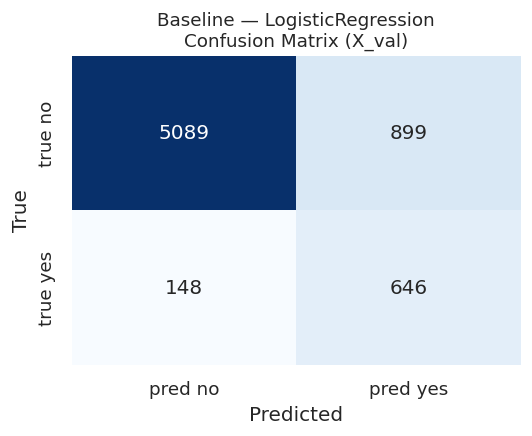

=== 2h. Tom tat baseline (de so sanh o Buoc 4) ===
  LogisticRegression | F1=0.5524 | ROC-AUC=0.9064 | PR-AUC=0.5503 | Recall(yes)=0.8136
  CM: TN=5089 FP=899 FN=148 TP=646  (val n=6782)
  -> Luu bien: baseline_df, pipe_lr, y_pred, y_proba de Buoc 3/4 tai su dung.


In [4]:
# ============================================================
# Buoc 2: Baseline Model — chi Logistic Regression (theo yeu cau)
# - Pipeline([('pre', preprocessor), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))])
# - Fit tren X_train -> predict tren X_val (giu X_test cho Buoc 6c)
# - Metric: F1, ROC-AUC, PR-AUC (Average Precision), Recall(yes) — bo qua Accuracy
# - Output: baseline_df + classification_report & confusion_matrix
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, roc_auc_score, average_precision_score,
    recall_score, classification_report, confusion_matrix
)

# --- 2a. Kiem tra tien dieu kien tu Buoc 1 ---
assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1 truoc"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1 truoc"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1 truoc (build_preprocessor())"
print(f"[2a] X_train={X_train.shape} y_train yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} y_val yes={y_val.mean()*100:.2f}%")
print(f"     preprocessor: {preprocessor}")

# --- 2b. Dung Pipeline duy nhat: preprocessor + LogisticRegression ---
# class_weight='balanced' de bu dap mat can 88:12; max_iter=1000 theo spec
pipe_lr = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, n_jobs=None)),
])
print("[2b] Pipeline:")
print(pipe_lr)

# --- 2c. Fit & predict tren X_val ---
pipe_lr.fit(X_train, y_train)
y_pred  = pipe_lr.predict(X_val)
# predict_proba co vi LogisticRegression ho tro; giu fallback neu doi clf sau nay
try:
    y_proba = pipe_lr.predict_proba(X_val)[:, 1]
except Exception as e:
    # fallback: decision_function -> min-max scale ve [0,1] de tinh ROC/PR tam
    print(f"  predict_proba khong kha dung ({e}) -> dung decision_function fallback")
    y_score = pipe_lr.decision_function(X_val)
    y_proba = (y_score - y_score.min()) / (y_score.max() - y_score.min() + 1e-12)

# --- 2d. Tinh 4 metric chinh (bo qua Accuracy) ---
f1     = f1_score(y_val, y_pred, zero_division=0)
roc    = roc_auc_score(y_val, y_proba)
prauc  = average_precision_score(y_val, y_proba)  # PR-AUC
rec_yes = recall_score(y_val, y_pred, pos_label=1, zero_division=0)

print("=== 2d. Metric tren X_val (val=6782, yes~11.7%) — bo qua Accuracy ===")
print(f"  F1 (yes)        = {f1:.4f}")
print(f"  ROC-AUC         = {roc:.4f}")
print(f"  PR-AUC (AP)     = {prauc:.4f}")
print(f"  Recall(yes)     = {rec_yes:.4f}")

# --- 2e. Gom baseline_df (1 dong LR) ---
baseline_df = pd.DataFrame([{
    "model": "LogisticRegression (class_weight=balanced)",
    "F1": f1,
    "ROC-AUC": roc,
    "PR-AUC": prauc,
    "Recall(yes)": rec_yes,
    "support_val": len(y_val),
    "note": "Pipeline(pre + LR) | bo qua Accuracy (Dummy ~88%)",
}])
# sap xep cot de doc de
baseline_df = baseline_df[["model", "F1", "ROC-AUC", "PR-AUC", "Recall(yes)", "support_val", "note"]]

print("=== 2e. baseline_df ===")
display(baseline_df.style.format({"F1": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Recall(yes)": "{:.4f}"}))

# --- 2f. classification_report & confusion_matrix ---
print("=== 2f. classification_report (val) ===")
print(classification_report(y_val, y_pred, digits=4, target_names=["no (0)", "yes (1)"], zero_division=0))

cm = confusion_matrix(y_val, y_pred)
print("=== confusion_matrix (rows=true, cols=pred) ===")
print("        pred  no  yes")
print(f" true no  {cm[0,0]:5d} {cm[0,1]:4d}")
print(f" true yes {cm[1,0]:5d} {cm[1,1]:4d}")
print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

# --- 2g. Heatmap confusion matrix ---
fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["pred no", "pred yes"], yticklabels=["true no", "true yes"])
ax.set_title("Baseline — LogisticRegression\nConfusion Matrix (X_val)", fontsize=11)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.show()

# --- 2h. Tom tat de Buoc 3 doi chieu ---
print("=== 2h. Tom tat baseline (de so sanh o Buoc 4) ===")
print(f"  LogisticRegression | F1={f1:.4f} | ROC-AUC={roc:.4f} | PR-AUC={prauc:.4f} | Recall(yes)={rec_yes:.4f}")
print(f"  CM: TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}  (val n={len(y_val)})")
print("  -> Luu bien: baseline_df, pipe_lr, y_pred, y_proba de Buoc 3/4 tai su dung.") 


## 3. Thử nghiệm nhiều Algorithm — (giới hạn 3 model)

> **Muc tieu:** So nhanh cac ho model khac nhau voi cung 1 `Pipeline([('pre', preprocessor), ('clf', ...)])`.
>
> **Pham vi lan nay (theo yeu cau): chi 3 thuat toan**
>
> | # | Model | Tham so chinh |
> |---|-------|---------------|
> | 1 | **RandomForest** | `n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1` |
> | 2 | **AdaBoost** | `n_estimators=200, learning_rate=0.8, random_state=42` — *khong co `class_weight` trong sklearn AdaBoost nen bo qua* |
> | 3 | **XGBoost** | `n_estimators=300, max_depth=6, learning_rate=0.05, scale_pos_weight≈7.6, random_state=42` — *tu bo qua neu chua `pip install xgboost`* |
>
> Tat ca `fit` tren `X_train` → danh gia tren `X_val` (giu `X_test` cho Buoc 6c), ghi `fit_time`.
> **Metric chinh:** `F1`, `ROC-AUC`, `PR-AUC`, `Recall(yes)` — sap xep `results_df` theo `F1` giam dan.
> `preprocessor` duoc `clone()` cho moi Pipeline de khong ro ri trang thai giua cac model.


In [5]:
# ============================================================
# Buoc 3: Thu nghiem nhieu Algorithm — chi 3 model
#   RandomForest (200 cay) | AdaBoost | XGBoost
# - Cung 1 preprocessor (clone moi pipeline)
# - class_weight='balanced' (XGBoost: scale_pos_weight~7.6)
# - random_state=42, fit_time, sort by F1
# ============================================================
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, recall_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# --- 3a. Kiem tra tien dieu kien ---
assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1 truoc"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1 truoc"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1 truoc"
print(f"[3a] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")

# --- 3b. Tinh scale_pos_weight cho XGBoost (ty le 0/1 tren train) ---
n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
scale_pos_weight = n_neg / max(n_pos, 1)
print(f"[3b] y_train 0/1 = {n_neg}/{n_pos}  -> scale_pos_weight={scale_pos_weight:.2f} (spec ~7.6)")

# --- 3c. Dinh nghia danh sach model (chi 3) ---
models = []

# 1) RandomForest — 200 cay, balanced
models.append((
    "RandomForest (200, balanced)",
    RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )
))

# 2) AdaBoost — khong co class_weight trong sklearn, dung SAMME
models.append((
    "AdaBoost (200, lr=0.8)",
    AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.8,
        algorithm="SAMME",
        random_state=42,
    )
))

# 3) XGBoost — thu import, neu thieu thi bo qua khong crash
try:
    from xgboost import XGBClassifier
    _has_xgb = True
except ImportError:
    _has_xgb = False
    print("  [warn] xgboost chua cai (pip install xgboost) -> bo qua XGBoost")

if _has_xgb:
    try:
        from xgboost import XGBClassifier as _XGB
        # thu xem param use_label_encoder con ton tai khong
        _probe = _XGB(n_estimators=10)
        _has_ule = "use_label_encoder" in _probe.get_params()
    except Exception:
        _has_ule = False
    _xgb_kwargs = dict(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        scale_pos_weight=round(float(scale_pos_weight), 2),
        random_state=42, n_jobs=-1, eval_metric="logloss",
    )
    if _has_ule:
        _xgb_kwargs["use_label_encoder"] = False
    models.append(("XGBoost (300, scale_pos_weight~7.6)", _XGB(**_xgb_kwargs)))

print(f"[3c] Se chay {len(models)} model: {[m[0] for m in models]}")

# --- 3d. Loop fit/predict tren X_val, ghi metric + fit_time ---
rows = []
for name, clf in models:
    pipe = Pipeline([("pre", clone(preprocessor)), ("clf", clf)])
    print(f"\n--- Fit: {name} ---")
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0

    y_pred = pipe.predict(X_val)
    try:
        y_proba = pipe.predict_proba(X_val)[:, 1]
    except Exception:
        try:
            y_score = pipe.decision_function(X_val)
            y_proba = (y_score - y_score.min()) / (y_score.max() - y_score.min() + 1e-12)
        except Exception:
            y_proba = y_pred.astype(float)

    f1  = f1_score(y_val, y_pred, zero_division=0)
    roc = roc_auc_score(y_val, y_proba)
    pr  = average_precision_score(y_val, y_proba)
    rec = recall_score(y_val, y_pred, pos_label=1, zero_division=0)

    print(f"  fit_time={fit_time:.2f}s | F1={f1:.4f} ROC-AUC={roc:.4f} PR-AUC={pr:.4f} Recall={rec:.4f}")
    rows.append({
        "model": name,
        "F1": f1,
        "ROC-AUC": roc,
        "PR-AUC": pr,
        "Recall(yes)": rec,
        "fit_time (s)": round(fit_time, 2),
        "support_val": len(y_val),
    })

# --- 3e. Gom results_df, sap xep theo F1 giam dan ---
results_df = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
results_df = results_df[["model", "F1", "ROC-AUC", "PR-AUC", "Recall(yes)", "fit_time (s)", "support_val"]]

print("\n=== 3e. results_df (sap xep theo F1 giam dan) ===")
try:
    from IPython.display import display as _display
except ImportError:
    _display = print
_display(results_df.style.format({"F1": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Recall(yes)": "{:.4f}", "fit_time (s)": "{:.2f}"}))

# --- 3f. Ghi chu de Buoc 4 so sanh ---
print("\n=== 3f. Tom tat ===")
for _, r in results_df.iterrows():
    print(f"  {r['model']:35s} | F1={r['F1']:.4f} ROC={r['ROC-AUC']:.4f} PR={r['PR-AUC']:.4f} Rec={r['Recall(yes)']:.4f} time={r['fit_time (s)']:.1f}s")
print("\nLuu bien: results_df (dung o Buoc 4).  X_test van chua dung (giu cho Buoc 6c).")


[3a] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%
[3b] y_train 0/1 = 27945/3702  -> scale_pos_weight=7.55 (spec ~7.6)
[3c] Se chay 3 model: ['RandomForest (200, balanced)', 'AdaBoost (200, lr=0.8)', 'XGBoost (300, scale_pos_weight~7.6)']

--- Fit: RandomForest (200, balanced) ---
  fit_time=4.89s | F1=0.4609 ROC-AUC=0.9354 PR-AUC=0.6367 Recall=0.3413

--- Fit: AdaBoost (200, lr=0.8) ---


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


  fit_time=5.45s | F1=0.4505 ROC-AUC=0.9109 PR-AUC=0.5689 Recall=0.3438

--- Fit: XGBoost (300, scale_pos_weight~7.6) ---
  fit_time=1.24s | F1=0.6023 ROC-AUC=0.9364 PR-AUC=0.6404 Recall=0.8451

=== 3e. results_df (sap xep theo F1 giam dan) ===


,model,F1,ROC-AUC,PR-AUC,Recall(yes),fit_time (s),support_val
0,"XGBoost (300, scale_pos_weight~7.6)",0.6023,0.9364,0.6404,0.8451,1.24,6782
1,"RandomForest (200, balanced)",0.4609,0.9354,0.6367,0.3413,4.89,6782
2,"AdaBoost (200, lr=0.8)",0.4505,0.9109,0.5689,0.3438,5.45,6782



=== 3f. Tom tat ===
  XGBoost (300, scale_pos_weight~7.6) | F1=0.6023 ROC=0.9364 PR=0.6404 Rec=0.8451 time=1.2s
  RandomForest (200, balanced)        | F1=0.4609 ROC=0.9354 PR=0.6367 Rec=0.3413 time=4.9s
  AdaBoost (200, lr=0.8)              | F1=0.4505 ROC=0.9109 PR=0.5689 Rec=0.3438 time=5.5s

Luu bien: results_df (dung o Buoc 4).  X_test van chua dung (giu cho Buoc 6c).


## 4. Danh gia & So sanh — Nhin mot lan la biet model nao thang

> **Muc tieu:** Gop `baseline_df` (Buoc 2) + `results_df` (Buoc 3) -> `results_all` sap xep theo `F1` (co the doi sang `PR-AUC` neu muon it lam phien khach hang) va ve **3 bo bieu do**.

| Bo | Hinh | Y nghia khi lech lop 88:12 |
|----|------|----------------------------|
| **4e** | Bar chart `F1 / ROC-AUC / PR-AUC` | So truc quan hieu nang tong hop |
| **4f** | `ROC Curve` + `PR Curve` overlay | **PR Curve quan trong nhat** khi duong tinh hiem |
| **4g** | Luoi `Confusion Matrix` | Thay ro danh doi `FP` vs `FN` |

> **4 model so sanh (nhu ban vua chay):** `LogisticRegression (balanced)` + `RandomForest (200)` + `AdaBoost (200)` + `XGBoost (300, scale_pos_weight~7.6)`. Neu thieu `xgboost` thi tu dong con 3 model, khong crash.
> Tat ca `Pipeline([('pre', clone(preprocessor)), ('clf', ...)])` — fit tren `X_train`, danh gia tren `X_val`, giu `X_test` cho Buoc 6c.
> **Output:** `results_all` (bang tong) + 3 hinh.


[4a] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%
  baseline_df: (1, 7)


,model,F1,ROC-AUC,PR-AUC,Recall(yes),support_val,note
0,LogisticRegression (class_weight=balanced),0.5524,0.9064,0.5503,0.8136,6782,Pipeline(pre + LR) | bo qua Accuracy (Dummy ~88%)


  results_df: (3, 7)


,model,F1,ROC-AUC,PR-AUC,Recall(yes),fit_time (s),support_val
0,"XGBoost (300, scale_pos_weight~7.6)",0.6023,0.9364,0.6404,0.8451,1.2400,6782
1,"RandomForest (200, balanced)",0.4609,0.9354,0.6367,0.3413,4.8900,6782
2,"AdaBoost (200, lr=0.8)",0.4505,0.9109,0.5689,0.3438,5.4500,6782


[4b] y 0/1 = 27945/3702 -> scale_pos_weight=7.55
  Se danh gia 4 model: ['LogisticRegression (balanced)', 'RandomForest (200, balanced)', 'AdaBoost (200, lr=0.8)', 'XGBoost (300, scale_pos_weight~7.6)']


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  LogisticRegression (balanced)          | F1=0.5524 ROC=0.9064 PR=0.5503 Rec=0.8136 time=9.54s  CM TN=5089 FP=899 FN=148 TP=646
  RandomForest (200, balanced)           | F1=0.4609 ROC=0.9354 PR=0.6367 Rec=0.3413 time=4.75s  CM TN=5877 FP=111 FN=523 TP=271


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


  AdaBoost (200, lr=0.8)                 | F1=0.4505 ROC=0.9109 PR=0.5689 Rec=0.3438 time=5.58s  CM TN=5843 FP=145 FN=521 TP=273
  XGBoost (300, scale_pos_weight~7.6)    | F1=0.6023 ROC=0.9364 PR=0.6404 Rec=0.8451 time=1.20s  CM TN=5225 FP=763 FN=123 TP=671

=== 4d. results_all (sap xep theo F1 giam dan, val n=6782, yes~11.7%) ===


,model,F1,ROC-AUC,PR-AUC,Recall(yes),fit_time (s),support_val
0,"XGBoost (300, scale_pos_weight~7.6)",0.6023,0.9364,0.6404,0.8451,1.20,6782
1,LogisticRegression (balanced),0.5524,0.9064,0.5503,0.8136,9.54,6782
2,"RandomForest (200, balanced)",0.4609,0.9354,0.6367,0.3413,4.75,6782
3,"AdaBoost (200, lr=0.8)",0.4505,0.9109,0.5689,0.3438,5.58,6782


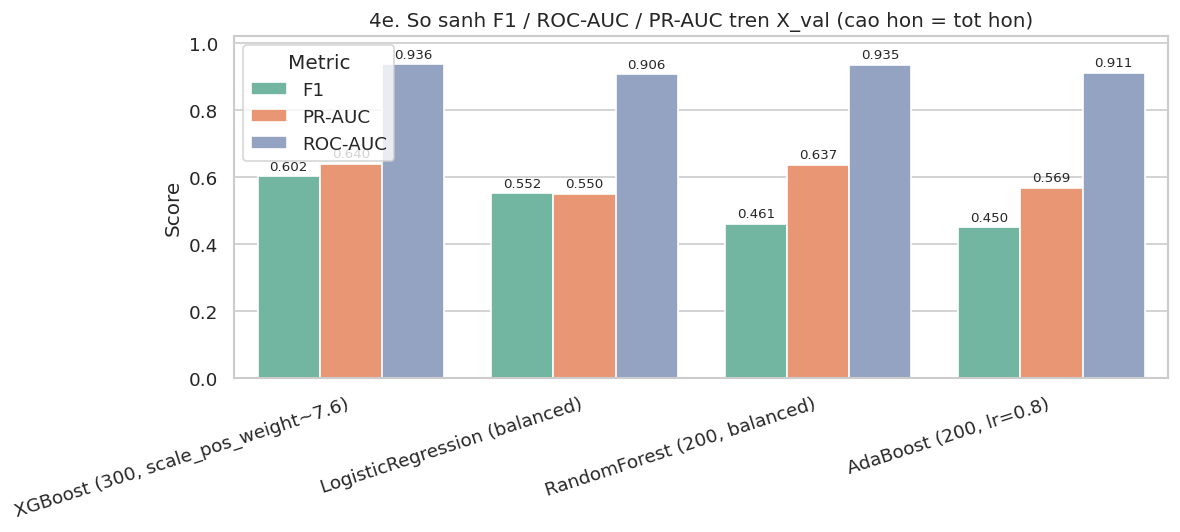

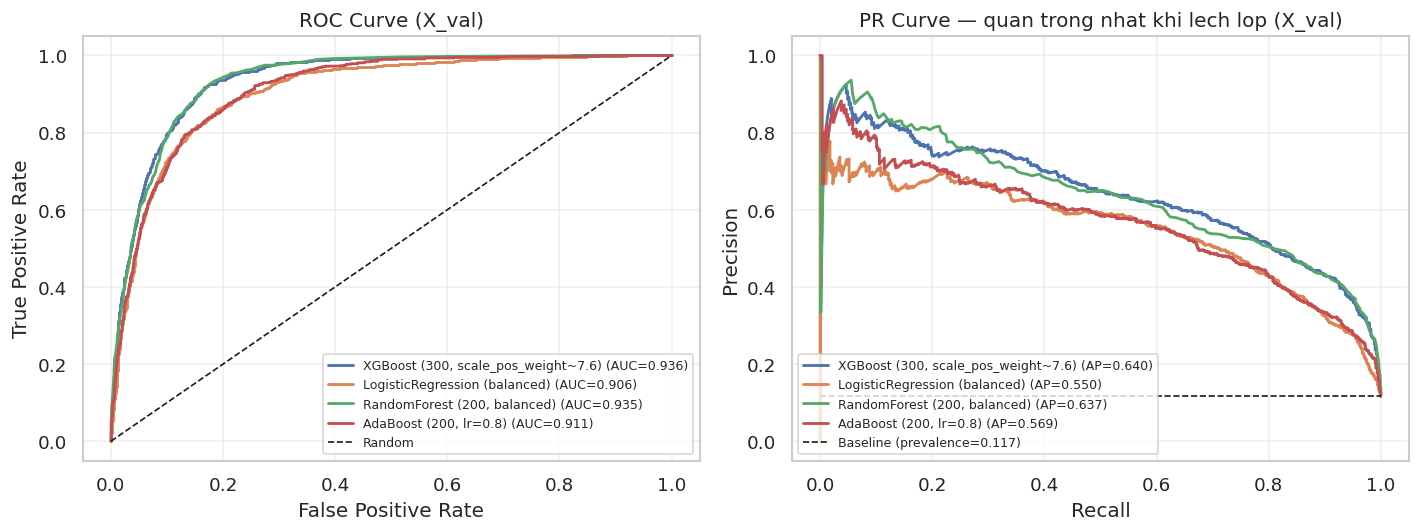

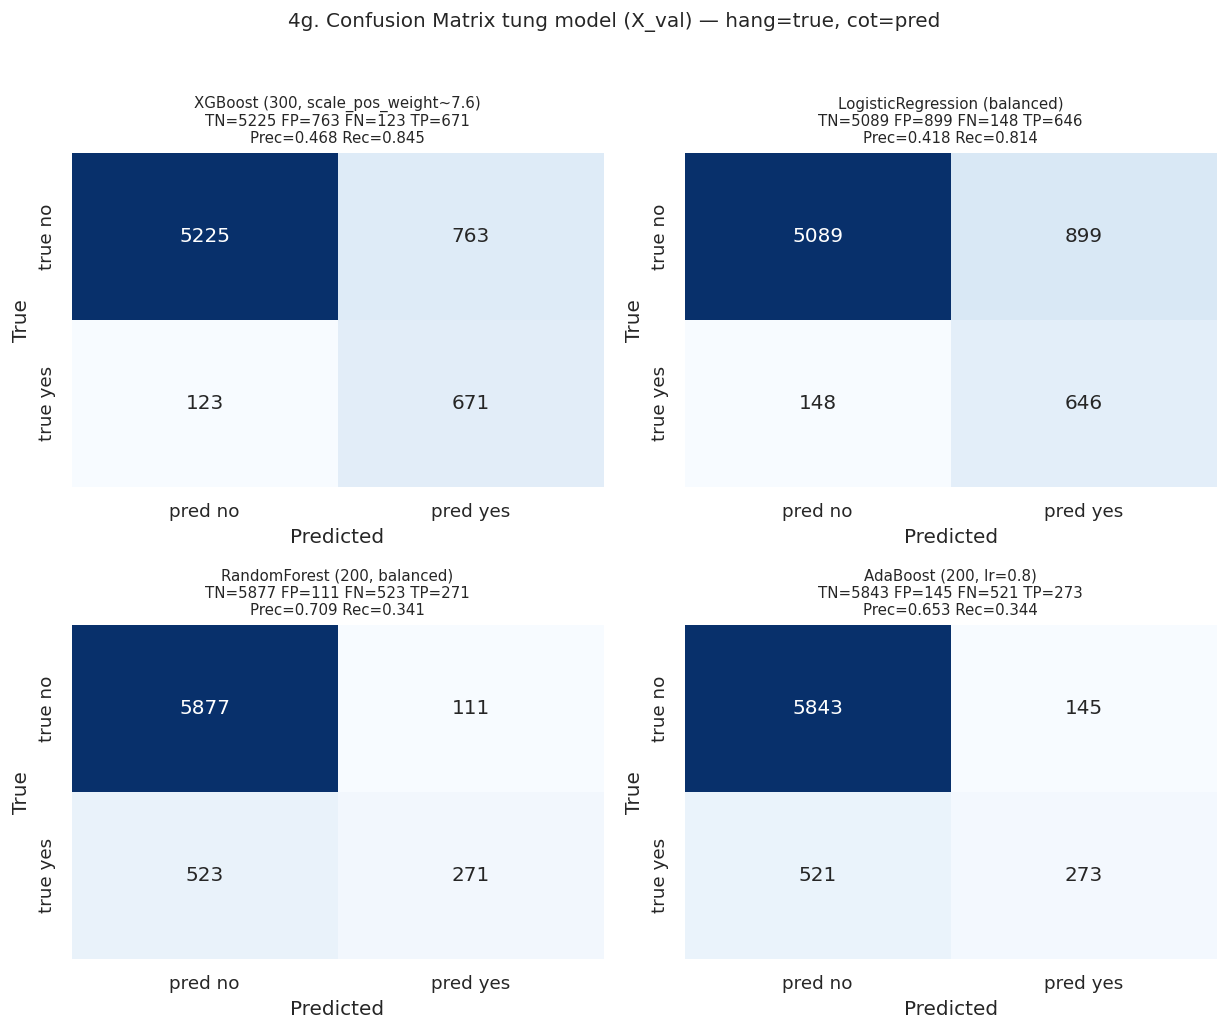

=== 4h. Tom tat (de chon Top-2 di tuning o Buoc 5) ===
  XGBoost (300, scale_pos_weight~7.6)    | F1=0.6023 ROC=0.9364 PR=0.6404 Rec=0.8451 time=1.2s
  LogisticRegression (balanced)          | F1=0.5524 ROC=0.9064 PR=0.5503 Rec=0.8136 time=9.5s
  RandomForest (200, balanced)           | F1=0.4609 ROC=0.9354 PR=0.6367 Rec=0.3413 time=4.8s
  AdaBoost (200, lr=0.8)                 | F1=0.4505 ROC=0.9109 PR=0.5689 Rec=0.3438 time=5.6s

  Thang theo F1    : XGBoost (300, scale_pos_weight~7.6) (F1=0.6023)
  Thang theo PR-AUC : XGBoost (300, scale_pos_weight~7.6) (PR-AUC=0.6404)  <- uu tien khi muon it lam phien khach hang
  Goi y: neu F1 va PR-AUC cung thang 1 model thi chon thang; neu khac nhau, dua ca 2 vao Buoc 5 tuning.

Luu bien: results_all, proba_store, pred_store, cm_store, pipe_store, plot_order, SORT_BY
X_test van chua dung — giu cho Buoc 6c (hold-out test).


In [6]:
# ============================================================
# Buoc 4: Danh gia & So sanh — 4 model (LR + RF + AdaBoost + XGBoost)
# - Gop baseline_df + results_df -> results_all (sort F1, co the doi PR-AUC)
# - Ve 3 bo: bar F1/ROC/PR | ROC+PR overlay | luoi Confusion Matrix
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    f1_score, roc_auc_score, average_precision_score, recall_score,
    confusion_matrix, roc_curve, precision_recall_curve
)
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

# --- 4a. Kiem tra tien dieu kien ---
assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[4a] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")
# baseline_df / results_df co the da co tu Buoc 2/3 — chi de doi chieu, Buoc 4 se fit lai de lay proba/CM
for _name in ["baseline_df", "results_df"]:
    if _name in globals():
        print(f"  {_name}: {globals()[_name].shape}")
        _display(globals()[_name])
    else:
        print(f"  {_name}: chua co (khong sao — Buoc 4 se tu fit lai)")

# --- 4b. Dinh nghia lai 4 model y nhu Buoc 2+3 (de lay proba/CM dong nhat) ---
n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
scale_pos_weight = n_neg / max(n_pos, 1)
print(f"[4b] y 0/1 = {n_neg}/{n_pos} -> scale_pos_weight={scale_pos_weight:.2f}")

model_specs = []
model_specs.append((
    "LogisticRegression (balanced)",
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
))
model_specs.append((
    "RandomForest (200, balanced)",
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1)
))
model_specs.append((
    "AdaBoost (200, lr=0.8)",
    AdaBoostClassifier(n_estimators=200, learning_rate=0.8, algorithm="SAMME", random_state=42)
))
_has_xgb = False
try:
    from xgboost import XGBClassifier
    _has_xgb = True
except ImportError:
    print("  [info] xgboost chua cai -> XGBoost se vang mat trong Buoc 4 (pip install xgboost de du 4 model)")

if _has_xgb:
    try:
        _probe = XGBClassifier(n_estimators=10)
        _has_ule = "use_label_encoder" in _probe.get_params()
    except Exception:
        _has_ule = False
    _kw = dict(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
               scale_pos_weight=round(float(scale_pos_weight),2), random_state=42, n_jobs=-1, eval_metric="logloss")
    if _has_ule:
        _kw["use_label_encoder"] = False
    model_specs.append(("XGBoost (300, scale_pos_weight~7.6)", XGBClassifier(**_kw)))

print(f"  Se danh gia {len(model_specs)} model: {[m[0] for m in model_specs]}")

# --- 4c. Fit lai tat ca, thu thap metric + proba + CM (clone preprocessor moi lan) ---
SORT_BY = "F1"  # doi thanh "PR-AUC" neu muon uu tien it lam phien khach hang
records = []
proba_store = {}  # name -> y_proba
pred_store  = {}  # name -> y_pred
cm_store    = {}  # name -> cm 2x2
pipe_store  = {}  # name -> pipeline (de dung lai o Buoc 5/6 neu can)

for name, clf in model_specs:
    pipe = Pipeline([("pre", clone(preprocessor)), ("clf", clf)])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    y_pred = pipe.predict(X_val)
    try:
        y_proba = pipe.predict_proba(X_val)[:, 1]
    except Exception:
        try:
            y_score = pipe.decision_function(X_val)
            y_proba = (y_score - y_score.min()) / (y_score.max() - y_score.min() + 1e-12)
        except Exception:
            y_proba = y_pred.astype(float)
    f1  = f1_score(y_val, y_pred, zero_division=0)
    roc = roc_auc_score(y_val, y_proba)
    pr  = average_precision_score(y_val, y_proba)
    rec = recall_score(y_val, y_pred, pos_label=1, zero_division=0)
    cm  = confusion_matrix(y_val, y_pred)
    print(f"  {name:38s} | F1={f1:.4f} ROC={roc:.4f} PR={pr:.4f} Rec={rec:.4f} time={fit_time:.2f}s  CM TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")
    records.append({"model": name, "F1": f1, "ROC-AUC": roc, "PR-AUC": pr, "Recall(yes)": rec, "fit_time (s)": round(fit_time,2), "support_val": len(y_val)})
    proba_store[name] = y_proba
    pred_store[name]  = y_pred
    cm_store[name]    = cm
    pipe_store[name]  = pipe

# --- 4d. Bang tong results_all ---
results_all = pd.DataFrame(records).sort_values(SORT_BY, ascending=False).reset_index(drop=True)
results_all = results_all[["model", "F1", "ROC-AUC", "PR-AUC", "Recall(yes)", "fit_time (s)", "support_val"]]
print(f"\n=== 4d. results_all (sap xep theo {SORT_BY} giam dan, val n={len(y_val)}, yes~{y_val.mean()*100:.1f}%) ===")
_display(results_all.style.format({"F1":"{:.4f}","ROC-AUC":"{:.4f}","PR-AUC":"{:.4f}","Recall(yes)":"{:.4f}","fit_time (s)":"{:.2f}"}).background_gradient(subset=["F1"], cmap="YlGn"))

# Giu thu tu hien thi theo F1 de ve bieu do nhat quan
plot_order = results_all["model"].tolist()

# --- 4e. Hinh 1: Bar chart F1 / ROC-AUC / PR-AUC ---
# Melt de ve grouped bar
melt = results_all.melt(id_vars="model", value_vars=["F1","ROC-AUC","PR-AUC"], var_name="metric", value_name="score")
# Sap xep model theo F1 de truc x co thu tu y nghia
melt["model"] = pd.Categorical(melt["model"], categories=plot_order, ordered=True)
melt = melt.sort_values(["model","metric"])

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(data=melt, x="model", y="score", hue="metric", palette="Set2", ax=ax)
ax.set_title("4e. So sanh F1 / ROC-AUC / PR-AUC tren X_val (cao hon = tot hon)", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.legend(title="Metric", loc="upper left")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

# --- 4f. Hinh 2: ROC Curve + PR Curve overlay ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# ROC
ax = axes[0]
for name in plot_order:
    fpr, tpr, _ = roc_curve(y_val, proba_store[name])
    roc = roc_auc_score(y_val, proba_store[name])
    ax.plot(fpr, tpr, lw=1.7, label=f"{name} (AUC={roc:.3f})")
ax.plot([0,1],[0,1],"k--", lw=1, label="Random")
ax.set_title("ROC Curve (X_val)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=7.5, loc="lower right")
ax.grid(alpha=0.3)

# PR — quan trong nhat khi lech lop
ax = axes[1]
prevalence = y_val.mean()
for name in plot_order:
    prec, rec, _ = precision_recall_curve(y_val, proba_store[name])
    ap = average_precision_score(y_val, proba_store[name])
    ax.plot(rec, prec, lw=1.7, label=f"{name} (AP={ap:.3f})")
ax.hlines(prevalence, 0, 1, colors="k", linestyles="--", lw=1, label=f"Baseline (prevalence={prevalence:.3f})")
ax.set_title("PR Curve — quan trong nhat khi lech lop (X_val)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(fontsize=7.5, loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- 4g. Hinh 3: Luoi Confusion Matrix cho tung model ---
n = len(plot_order)
ncols = 2 if n >= 3 else n
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.2*nrows), squeeze=False)
axes = axes.flatten()
for idx, name in enumerate(plot_order):
    ax = axes[idx]
    cm = cm_store[name]
    rec = records[[r["model"] for r in records].index(name)]["Recall(yes)"]
    # dung Blues, annot so luong
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred no","pred yes"], yticklabels=["true no","true yes"])
    # them ti le: precision/recall tren title
    tn, fp, fn, tp = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    prec = tp / max(tp+fp, 1)
    ax.set_title(f"{name}\nTN={tn} FP={fp} FN={fn} TP={tp}\nPrec={prec:.3f} Rec={rec:.3f}", fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
# an o thua neu le
for j in range(n, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle("4g. Confusion Matrix tung model (X_val) — hang=true, cot=pred", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

# --- 4h. Tom tat de chon model di tiep Buoc 5 ---
print("=== 4h. Tom tat (de chon Top-2 di tuning o Buoc 5) ===")
for _, r in results_all.iterrows():
    print(f"  {r['model']:38s} | F1={r['F1']:.4f} ROC={r['ROC-AUC']:.4f} PR={r['PR-AUC']:.4f} Rec={r['Recall(yes)']:.4f} time={r['fit_time (s)']:.1f}s")
best_f1 = results_all.iloc[0]
best_pr = results_all.sort_values('PR-AUC', ascending=False).iloc[0]
print(f"\n  Thang theo F1    : {best_f1['model']} (F1={best_f1['F1']:.4f})")
print(f"  Thang theo PR-AUC : {best_pr['model']} (PR-AUC={best_pr['PR-AUC']:.4f})  <- uu tien khi muon it lam phien khach hang")
print("  Goi y: neu F1 va PR-AUC cung thang 1 model thi chon thang; neu khac nhau, dua ca 2 vao Buoc 5 tuning.")
print("\nLuu bien: results_all, proba_store, pred_store, cm_store, pipe_store, plot_order, SORT_BY")
print("X_test van chua dung — giu cho Buoc 6c (hold-out test).")


## 4.5. Đo hàm LOSS của các phương pháp
> **Vấn đề:** Notebook này chỉ ghi lại các metric phân loại (`F1`, `ROC-AUC`, `PR-AUC`, `Recall`) — **không có cell nào đo được hàm loss**.
> - `LogisticRegression` / `RandomForest` / `AdaBoost` (scikit-learn) **không lưu loss history** → tính `log_loss` **sau khi fit** trên `X_val`.
> - `XGBoost` có thể lấy **loss history theo từng booster** bằng `eval_set` + `evals_result`.
> Cell này fit lại 4 model riêng (dùng `clone(preprocessor)`) — không ảnh hưởng Bước 5/6.

In [7]:
# ============================================================
# 4.5. Đo hàm LOSS của 4 model (LR + RF + AdaBoost + XGBoost) trên X_val
# - LR / RF / AdaBoost (scikit-learn) KHÔNG lưu loss history
#   -> tính log_loss sau khi fit từ predict_proba.
# - XGBoost có thể lấy loss history từng booster (evals_result).
# ============================================================
import numpy as np
from sklearn.metrics import log_loss
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

assert 'X_train' in globals() and 'y_train' in globals(), "Chưa có X_train/y_train — chạy Bước 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chưa có X_val/y_val — chạy Bước 1"
assert 'preprocessor' in globals(), "Chưa có preprocessor — chạy Bước 1"

n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
spw = float(n_neg / n_pos)
print(f"[4.5] n_pos={n_pos} n_neg={n_neg} scale_pos_weight={spw:.2f}")

def _logloss(clf, name):
    pipe = Pipeline([('pre', clone(preprocessor)), ('clf', clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]
    loss = log_loss(y_val, proba)
    print(f"  {name:42s} | log_loss(val) = {loss:.4f}")
    return loss

losses = {}
# --- 1. LogisticRegression ---
losses['LogisticRegression'] = _logloss(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'LogisticRegression (balanced)')

# --- 2. RandomForest ---
losses['RandomForest'] = _logloss(
    RandomForestClassifier(n_estimators=200, class_weight='balanced',
                           random_state=42, n_jobs=-1),
    'RandomForest (200, balanced)')

# --- 3. AdaBoost ---
losses['AdaBoost'] = _logloss(
    AdaBoostClassifier(n_estimators=200, learning_rate=0.8, random_state=42),
    'AdaBoost (200, lr=0.8)')

# --- 4. XGBoost — có loss history theo từng booster ---
try:
    from xgboost import XGBClassifier
    _xgb_clf = XGBClassifier(n_estimators=300, scale_pos_weight=spw,
                             random_state=42, n_jobs=-1, eval_metric='logloss')
    # eval_set phải là dữ liệu ĐÃ transform (qua preprocessor)
    _pre = clone(preprocessor).fit(X_train, y_train)
    X_train_t, X_val_t = _pre.transform(X_train), _pre.transform(X_val)
    
    # XGBoost 2.0+: không dùng tham số evals_result nữa
    _xgb_clf.fit(X_train_t, y_train,
                 eval_set=[(X_val_t, y_val)],
                 verbose=False)
    
    # Lấy kết quả evaluation từ method .evals_result()
    evals_result = _xgb_clf.evals_result()
    
    pipe_xgb = Pipeline([('pre', _pre), ('clf', _xgb_clf)])
    proba = pipe_xgb.predict_proba(X_val)[:, 1]
    losses['XGBoost'] = log_loss(y_val, proba)
    # XGBoost >= 1.6 dùng 'validation_0', cũ dùng 'eval_0'
    hist_key = 'validation_0' if 'validation_0' in evals_result else 'eval_0'
    hist = evals_result[hist_key]['logloss']
    print(f"  {'XGBoost (300, scale_pos_weight~7.6)':42s} | log_loss(val) = {losses['XGBoost']:.4f}")
    print(f"  [XGB loss history] n_estimators = {len(hist)}")
    print(f"    first 5 : {[round(h, 4) for h in hist[:5]]}")
    print(f"    last  5 : {[round(h, 4) for h in hist[-5:]]}")
    print(f"    min loss = {min(hist):.4f} (booster #{hist.index(min(hist)) + 1})")
except ImportError:
    print("  [bỏ qua] xgboost chưa cài")

print("--- Tóm tắt log_loss(val) ---")
for k, v in losses.items():
    print(f"  {k:20s}: {v:.4f}")


[4.5] n_pos=3702 n_neg=27945 scale_pos_weight=7.55


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  LogisticRegression (balanced)              | log_loss(val) = 0.4119
  RandomForest (200, balanced)               | log_loss(val) = 0.2024
  AdaBoost (200, lr=0.8)                     | log_loss(val) = 0.4991
  XGBoost (300, scale_pos_weight~7.6)        | log_loss(val) = 0.2535
  [XGB loss history] n_estimators = 300
    first 5 : [0.567, 0.4976, 0.4507, 0.4216, 0.3989]
    last  5 : [0.2537, 0.2537, 0.2538, 0.2535, 0.2535]
    min loss = 0.2532 (booster #207)
--- Tóm tắt log_loss(val) ---
  LogisticRegression  : 0.4119
  RandomForest        : 0.2024
  AdaBoost            : 0.4991
  XGBoost             : 0.2535


## 5. Tinh chinh Tham so — tim bo tham so toi uu cho ca 4 model

> **Muc tieu:** Tim bo tham so tot nhat cho **ca 4 model** (khong chi Top-2), moi model 1 cell rieng.

| Cell | Model | Search chinh | Search phu (tuy chon) |
|------|-------|--------------|-----------------------|
| **5.1** | LogisticRegression | `RandomizedSearchCV(n_iter=18, cv=StratifiedKFold(5), scoring='f1')` | Optuna 25 trials `average_precision` |
| **5.2** | RandomForest | nhu tren | nhu tren |
| **5.3** | AdaBoost | nhu tren | nhu tren |
| **5.4** | XGBoost | nhu tren | nhu tren |

> **Chong leakage:** Moi lan search `fit` ca `preprocessor` **ben trong `Pipeline` + ben trong CV** (`Pipeline([('pre', clone(preprocessor)), ('clf', ...)])`), khong `fit` ngoai.
> **Danh gia:** `before` = param mac dinh (Buoc 2/3) tren `X_val`, `after` = `best_estimator_` tren `X_val`. So sanh bang bang + bar chart `Delta = after - before`.
> **XGBoost / Optuna** tu bo qua neu chua `pip install`, khong crash notebook. Giu `X_test` cho Buoc 6c.
> **Output moi cell:** `tuned_51_lr` / `tuned_52_rf` / `tuned_53_ada` / `tuned_54_xgb` + `compare_5x_df` + `tuned_results` tong hop (o 5.4).


### 5.1 LogisticRegression — RandomizedSearchCV + Optuna (tuy chon)


[5.1] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%
  before (default) | F1=0.5524 ROC=0.9064 PR=0.5503 Rec=0.8136
Fitting 5 folds for each of 18 candidates, totalling 90 fits


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  RandomizedSearchCV done in 485.9s
  best F1 (CV)=0.5513 | best_params={'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__class_weight': 'balanced', 'clf__C': 1}
  after  (tuned)  | F1=0.5569 ROC=0.9101 PR=0.5566 Rec=0.8010

=== 5.1 compare (X_val) ===


,version,F1,ROC-AUC,PR-AUC,Recall,cv_best_F1,Delta,d_ROC-AUC,d_PR-AUC,d_Recall
0,before (default),0.5524,0.9064,0.5503,0.8136,nan,0.0000,nan,nan,nan
1,after (tuned),0.5569,0.9101,0.5566,0.8010,0.5513,0.0045,0.0038,0.0064,-0.0126


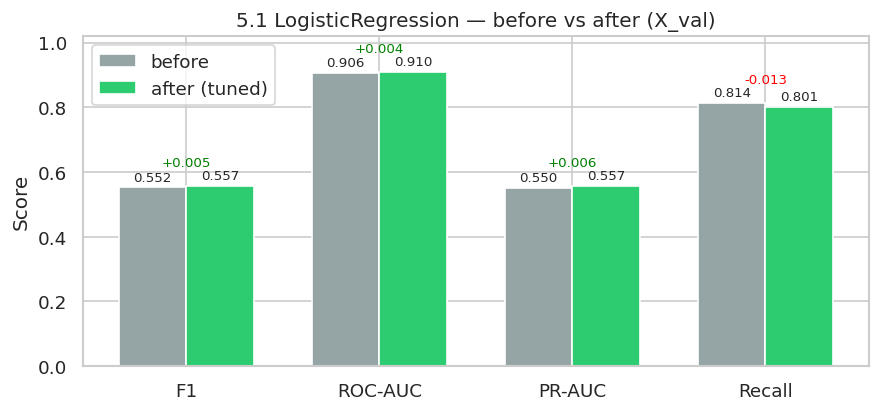


Luu: tuned_51_lr (best_params={'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__class_weight': 'balanced', 'clf__C': 1})

[info] optuna chua cai -> bo qua Optuna (pip install optuna de chay 25 trials)


In [8]:
# ============================================================
# 5.1 LogisticRegression — tim tham so toi uu
# - RandomizedSearchCV(n_iter=18, cv=StratifiedKFold(5), scoring='f1')
# - fit ca preprocessor ben trong CV (Pipeline + clone) -> khong leakage
# - Optuna 25 trials scoring=average_precision (chi chay neu pip install optuna)
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[5.1] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")

# --- before: param mac dinh nhu Buoc 2 ---
pipe_before_lr = Pipeline([('pre', clone(preprocessor)), ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])
pipe_before_lr.fit(X_train, y_train)
y_pred_b = pipe_before_lr.predict(X_val)
try:
    y_proba_b = pipe_before_lr.predict_proba(X_val)[:,1]
except Exception:
    y_proba_b = pipe_before_lr.decision_function(X_val)
    y_proba_b = (y_proba_b - y_proba_b.min())/(y_proba_b.max()-y_proba_b.min()+1e-12)
before_lr = {"F1": f1_score(y_val, y_pred_b, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_b), "PR-AUC": average_precision_score(y_val, y_proba_b), "Recall": recall_score(y_val, y_pred_b, zero_division=0)}
print(f"  before (default) | F1={before_lr['F1']:.4f} ROC={before_lr['ROC-AUC']:.4f} PR={before_lr['PR-AUC']:.4f} Rec={before_lr['Recall']:.4f}")

# --- RandomizedSearchCV ---
pipe_lr = Pipeline([('pre', clone(preprocessor)), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
param_dist_lr = {
    'clf__C': [0.01, 0.03, 0.05, 0.1, 0.3, 0.5, 1, 3, 10],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver': ['liblinear', 'saga'],
    'clf__class_weight': ['balanced', None],
}
# saga + l1 can max_iter lon hon, nhung da de 1000
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_lr = RandomizedSearchCV(pipe_lr, param_dist_lr, n_iter=18, cv=cv, scoring='f1', n_jobs=-1, random_state=42, verbose=1, error_score='raise')
t0 = time.perf_counter()
search_lr.fit(X_train, y_train)
print(f"  RandomizedSearchCV done in {time.perf_counter()-t0:.1f}s")
print(f"  best F1 (CV)={search_lr.best_score_:.4f} | best_params={search_lr.best_params_}")

# --- after: best_estimator_ tren X_val ---
pipe_after_lr = search_lr.best_estimator_
y_pred_a = pipe_after_lr.predict(X_val)
try:
    y_proba_a = pipe_after_lr.predict_proba(X_val)[:,1]
except Exception:
    y_proba_a = pipe_after_lr.decision_function(X_val)
    y_proba_a = (y_proba_a - y_proba_a.min())/(y_proba_a.max()-y_proba_a.min()+1e-12)
after_lr = {"F1": f1_score(y_val, y_pred_a, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_a), "PR-AUC": average_precision_score(y_val, y_proba_a), "Recall": recall_score(y_val, y_pred_a, zero_division=0)}
print(f"  after  (tuned)  | F1={after_lr['F1']:.4f} ROC={after_lr['ROC-AUC']:.4f} PR={after_lr['PR-AUC']:.4f} Rec={after_lr['Recall']:.4f}")

compare_51_df = pd.DataFrame([
    {"version": "before (default)", **before_lr, "cv_best_F1": np.nan},
    {"version": "after (tuned)",    **after_lr,  "cv_best_F1": search_lr.best_score_},
])
compare_51_df["Delta"] = compare_51_df["F1"] - before_lr["F1"]
# Delta cot rieng cho F1 de de doc; cac metric khac delta tinh tam
for col in ["ROC-AUC","PR-AUC","Recall"]:
    compare_51_df.loc[1, f"d_{col}"] = after_lr[col] - before_lr[col]
print("\n=== 5.1 compare (X_val) ===")
_display(compare_51_df.style.format({"F1":"{:.4f}","ROC-AUC":"{:.4f}","PR-AUC":"{:.4f}","Recall":"{:.4f}","cv_best_F1":"{:.4f}","Delta":"{:.4f}","d_ROC-AUC":"{:.4f}","d_PR-AUC":"{:.4f}","d_Recall":"{:.4f}"}))

# bar chart Delta
fig, ax = plt.subplots(figsize=(7.5, 3.6))
metrics = ["F1","ROC-AUC","PR-AUC","Recall"]
x = np.arange(len(metrics))
b = [before_lr[m] for m in metrics]
a = [after_lr[m] for m in metrics]
w=0.35
ax.bar(x-w/2, b, w, label="before", color="#95a5a6")
ax.bar(x+w/2, a, w, label="after (tuned)", color="#2ecc71")
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0,1.02); ax.set_ylabel("Score"); ax.legend()
ax.set_title("5.1 LogisticRegression — before vs after (X_val)")
for i,(bv,av) in enumerate(zip(b,a)):
    ax.text(i-w/2, bv+0.02, f"{bv:.3f}", ha="center", fontsize=8)
    ax.text(i+w/2, av+0.02, f"{av:.3f}", ha="center", fontsize=8)
    d = av-bv
    ax.text(i, max(bv,av)+0.06, f"{d:+.3f}", ha="center", fontsize=8, color="green" if d>=0 else "red")
plt.tight_layout(); plt.show()

tuned_51_lr = {"model": "LogisticRegression", "best_params": search_lr.best_params_, "cv_best_F1": float(search_lr.best_score_), "before": before_lr, "after": after_lr, "best_estimator": pipe_after_lr, "search": search_lr}
print(f"\nLuu: tuned_51_lr (best_params={search_lr.best_params_})")

# --- Optuna tuy chon (25 trials, scoring=average_precision) ---
try:
    import optuna
    from sklearn.model_selection import cross_val_score
    print("\n--- Optuna (25 trials, scoring=average_precision) ---")
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective_lr(trial):
        C = trial.suggest_float("C", 0.01, 10, log=True)
        penalty = trial.suggest_categorical("penalty", ["l1","l2"])
        solver = trial.suggest_categorical("solver", ["liblinear","saga"])
        cw = trial.suggest_categorical("class_weight", ["balanced", None])
        # liblinear + saga deu ho tro l1/l2 nen khong can loai
        clf = LogisticRegression(C=C, penalty=penalty, solver=solver, class_weight=cw, max_iter=1000, random_state=42)
        pipe = Pipeline([('pre', clone(preprocessor)), ('clf', clf)])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
        return scores.mean()
    study_lr = optuna.create_study(direction="maximize")
    study_lr.optimize(objective_lr, n_trials=25, show_progress_bar=True)
    print(f"  Optuna best AP={study_lr.best_value:.4f} | params={study_lr.best_params}")
    # fit lai best optuna tren full train va danh gia X_val
    bp = study_lr.best_params
    clf_opt = LogisticRegression(C=bp["C"], penalty=bp["penalty"], solver=bp["solver"], class_weight=bp["class_weight"], max_iter=1000, random_state=42)
    pipe_opt_lr = Pipeline([('pre', clone(preprocessor)), ('clf', clf_opt)])
    pipe_opt_lr.fit(X_train, y_train)
    yp = pipe_opt_lr.predict(X_val)
    try: ypr = pipe_opt_lr.predict_proba(X_val)[:,1]
    except Exception: ypr = yp.astype(float)
    opt_after = {"F1": f1_score(y_val, yp, zero_division=0), "PR-AUC": average_precision_score(y_val, ypr), "ROC-AUC": roc_auc_score(y_val, ypr)}
    print(f"  Optuna on X_val | F1={opt_after['F1']:.4f} PR={opt_after['PR-AUC']:.4f} ROC={opt_after['ROC-AUC']:.4f}")
    tuned_51_lr["optuna_best_params"] = bp
    tuned_51_lr["optuna_best_AP"] = float(study_lr.best_value)
    tuned_51_lr["optuna_val_metrics"] = opt_after
except ImportError:
    print("\n[info] optuna chua cai -> bo qua Optuna (pip install optuna de chay 25 trials)")
except Exception as e:
    print(f"\n[warn] Optuna loi: {e}")


### 5.2 RandomForest — RandomizedSearchCV + Optuna (tuy chon)


[5.2] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%
  before (default) | F1=0.4609 ROC=0.9354 PR=0.6367 Rec=0.3413
Fitting 5 folds for each of 18 candidates, totalling 90 fits
  RandomizedSearchCV done in 1092.2s
  best F1 (CV)=0.6160 | best_params={'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 4, 'clf__max_features': None, 'clf__max_depth': 30, 'clf__class_weight': 'balanced_subsample'}
  after  (tuned)  | F1=0.6225 ROC=0.9341 PR=0.6297 Rec=0.7040

=== 5.2 compare (X_val) ===


,version,F1,ROC-AUC,PR-AUC,Recall,cv_best_F1,Delta_F1,d_ROC-AUC,d_PR-AUC,d_Recall
0,before (default),0.4609,0.9354,0.6367,0.3413,nan,0.0000,nan,nan,nan
1,after (tuned),0.6225,0.9341,0.6297,0.7040,0.6160,0.1616,-0.0013,-0.0070,0.3627


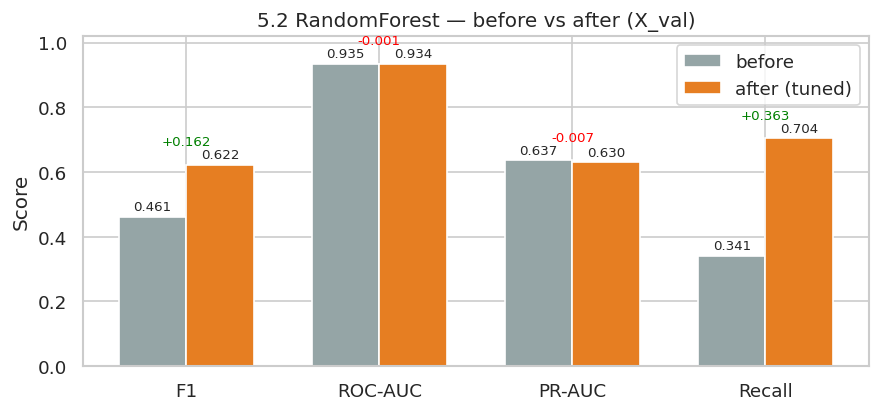


Luu: tuned_52_rf (best_params={'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 4, 'clf__max_features': None, 'clf__max_depth': 30, 'clf__class_weight': 'balanced_subsample'})

[info] optuna chua cai -> bo qua Optuna (pip install optuna)


In [9]:
# ============================================================
# 5.2 RandomForest — tim tham so toi uu
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[5.2] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")

pipe_before_rf = Pipeline([('pre', clone(preprocessor)), ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1))])
pipe_before_rf.fit(X_train, y_train)
y_pred_b = pipe_before_rf.predict(X_val)
y_proba_b = pipe_before_rf.predict_proba(X_val)[:,1]
before_rf = {"F1": f1_score(y_val, y_pred_b, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_b), "PR-AUC": average_precision_score(y_val, y_proba_b), "Recall": recall_score(y_val, y_pred_b, zero_division=0)}
print(f"  before (default) | F1={before_rf['F1']:.4f} ROC={before_rf['ROC-AUC']:.4f} PR={before_rf['PR-AUC']:.4f} Rec={before_rf['Recall']:.4f}")

pipe_rf = Pipeline([('pre', clone(preprocessor)), ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))])
param_dist_rf = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__max_depth': [None, 8, 12, 16, 20, 30],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__max_features': ['sqrt', 'log2', None],
    'clf__class_weight': ['balanced', 'balanced_subsample', None],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_rf = RandomizedSearchCV(pipe_rf, param_dist_rf, n_iter=18, cv=cv, scoring='f1', n_jobs=-1, random_state=42, verbose=1, error_score='raise')
t0 = time.perf_counter()
search_rf.fit(X_train, y_train)
print(f"  RandomizedSearchCV done in {time.perf_counter()-t0:.1f}s")
print(f"  best F1 (CV)={search_rf.best_score_:.4f} | best_params={search_rf.best_params_}")

pipe_after_rf = search_rf.best_estimator_
y_pred_a = pipe_after_rf.predict(X_val)
y_proba_a = pipe_after_rf.predict_proba(X_val)[:,1]
after_rf = {"F1": f1_score(y_val, y_pred_a, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_a), "PR-AUC": average_precision_score(y_val, y_proba_a), "Recall": recall_score(y_val, y_pred_a, zero_division=0)}
print(f"  after  (tuned)  | F1={after_rf['F1']:.4f} ROC={after_rf['ROC-AUC']:.4f} PR={after_rf['PR-AUC']:.4f} Rec={after_rf['Recall']:.4f}")

compare_52_df = pd.DataFrame([
    {"version": "before (default)", **before_rf, "cv_best_F1": np.nan},
    {"version": "after (tuned)",    **after_rf,  "cv_best_F1": search_rf.best_score_},
])
compare_52_df["Delta_F1"] = compare_52_df["F1"] - before_rf["F1"]
for col in ["ROC-AUC","PR-AUC","Recall"]:
    compare_52_df.loc[1, f"d_{col}"] = after_rf[col] - before_rf[col]
print("\n=== 5.2 compare (X_val) ===")
_display(compare_52_df.style.format({"F1":"{:.4f}","ROC-AUC":"{:.4f}","PR-AUC":"{:.4f}","Recall":"{:.4f}","cv_best_F1":"{:.4f}","Delta_F1":"{:.4f}","d_ROC-AUC":"{:.4f}","d_PR-AUC":"{:.4f}","d_Recall":"{:.4f}"}))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
metrics = ["F1","ROC-AUC","PR-AUC","Recall"]
x = np.arange(len(metrics)); b=[before_rf[m] for m in metrics]; a=[after_rf[m] for m in metrics]; w=0.35
ax.bar(x-w/2, b, w, label="before", color="#95a5a6"); ax.bar(x+w/2, a, w, label="after (tuned)", color="#e67e22")
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0,1.02); ax.set_ylabel("Score"); ax.legend()
ax.set_title("5.2 RandomForest — before vs after (X_val)")
for i,(bv,av) in enumerate(zip(b,a)):
    ax.text(i-w/2, bv+0.02, f"{bv:.3f}", ha="center", fontsize=8)
    ax.text(i+w/2, av+0.02, f"{av:.3f}", ha="center", fontsize=8)
    d=av-bv; ax.text(i, max(bv,av)+0.06, f"{d:+.3f}", ha="center", fontsize=8, color="green" if d>=0 else "red")
plt.tight_layout(); plt.show()

tuned_52_rf = {"model": "RandomForest", "best_params": search_rf.best_params_, "cv_best_F1": float(search_rf.best_score_), "before": before_rf, "after": after_rf, "best_estimator": pipe_after_rf, "search": search_rf}
print(f"\nLuu: tuned_52_rf (best_params={search_rf.best_params_})")

try:
    import optuna
    from sklearn.model_selection import cross_val_score
    print("\n--- Optuna (25 trials, scoring=average_precision) ---")
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective_rf(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
            "max_depth": trial.suggest_categorical("max_depth", [None, 8, 12, 16, 20, 30]),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 4),
            "max_features": trial.suggest_categorical("max_features", ["sqrt","log2", None]),
            "class_weight": trial.suggest_categorical("class_weight", ["balanced","balanced_subsample", None]),
            "random_state": 42, "n_jobs": -1,
        }
        clf = RandomForestClassifier(**params)
        pipe = Pipeline([('pre', clone(preprocessor)), ('clf', clf)])
        return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1).mean()
    study_rf = optuna.create_study(direction="maximize")
    study_rf.optimize(objective_rf, n_trials=25, show_progress_bar=True)
    print(f"  Optuna best AP={study_rf.best_value:.4f} | params={study_rf.best_params}")
    bp = study_rf.best_params; bp["random_state"]=42; bp["n_jobs"]=-1
    pipe_opt = Pipeline([('pre', clone(preprocessor)), ('clf', RandomForestClassifier(**bp))])
    pipe_opt.fit(X_train, y_train)
    yp = pipe_opt.predict(X_val); ypr = pipe_opt.predict_proba(X_val)[:,1]
    opt_after = {"F1": f1_score(y_val, yp, zero_division=0), "PR-AUC": average_precision_score(y_val, ypr), "ROC-AUC": roc_auc_score(y_val, ypr)}
    print(f"  Optuna on X_val | F1={opt_after['F1']:.4f} PR={opt_after['PR-AUC']:.4f} ROC={opt_after['ROC-AUC']:.4f}")
    tuned_52_rf["optuna_best_params"]=study_rf.best_params; tuned_52_rf["optuna_best_AP"]=float(study_rf.best_value); tuned_52_rf["optuna_val_metrics"]=opt_after
except ImportError:
    print("\n[info] optuna chua cai -> bo qua Optuna (pip install optuna)")
except Exception as e:
    print(f"\n[warn] Optuna loi: {e}")


### 5.3 AdaBoost — RandomizedSearchCV + Optuna (tuy chon)


[5.3] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


  before (default) | F1=0.4505 ROC=0.9109 PR=0.5689 Rec=0.3438
Fitting 5 folds for each of 18 candidates, totalling 90 fits


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


  RandomizedSearchCV done in 295.0s
  best F1 (CV)=0.4643 | best_params={'clf__n_estimators': 300, 'clf__learning_rate': 1.2}
  after  (tuned)  | F1=0.4831 ROC=0.9175 PR=0.5828 Rec=0.3866

=== 5.3 compare (X_val) ===


,version,F1,ROC-AUC,PR-AUC,Recall,cv_best_F1,Delta_F1,d_ROC-AUC,d_PR-AUC,d_Recall
0,before (default),0.4505,0.9109,0.5689,0.3438,nan,0.0000,nan,nan,nan
1,after (tuned),0.4831,0.9175,0.5828,0.3866,0.4643,0.0326,0.0066,0.0139,0.0428


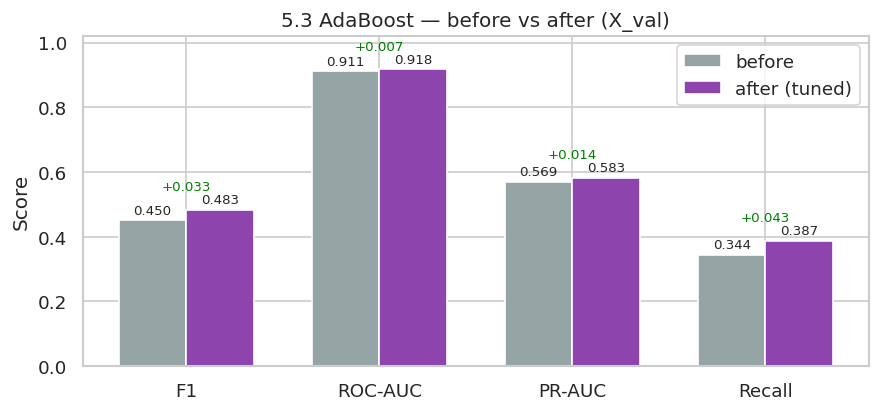


Luu: tuned_53_ada (best_params={'clf__n_estimators': 300, 'clf__learning_rate': 1.2})

[info] optuna chua cai -> bo qua Optuna (pip install optuna)


In [10]:
# ============================================================
# 5.3 AdaBoost — tim tham so toi uu
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[5.3] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")

pipe_before_ada = Pipeline([('pre', clone(preprocessor)), ('clf', AdaBoostClassifier(n_estimators=200, learning_rate=0.8, algorithm='SAMME', random_state=42))])
pipe_before_ada.fit(X_train, y_train)
y_pred_b = pipe_before_ada.predict(X_val)
try: y_proba_b = pipe_before_ada.predict_proba(X_val)[:,1]
except Exception: y_proba_b = y_pred_b.astype(float)
before_ada = {"F1": f1_score(y_val, y_pred_b, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_b), "PR-AUC": average_precision_score(y_val, y_proba_b), "Recall": recall_score(y_val, y_pred_b, zero_division=0)}
print(f"  before (default) | F1={before_ada['F1']:.4f} ROC={before_ada['ROC-AUC']:.4f} PR={before_ada['PR-AUC']:.4f} Rec={before_ada['Recall']:.4f}")

pipe_ada = Pipeline([('pre', clone(preprocessor)), ('clf', AdaBoostClassifier(algorithm='SAMME', random_state=42))])
param_dist_ada = {
    'clf__n_estimators': [50, 100, 200, 300, 400],
    'clf__learning_rate': [0.3, 0.5, 0.8, 1.0, 1.2],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search_ada = RandomizedSearchCV(pipe_ada, param_dist_ada, n_iter=18, cv=cv, scoring='f1', n_jobs=-1, random_state=42, verbose=1, error_score='raise')
t0 = time.perf_counter()
search_ada.fit(X_train, y_train)
print(f"  RandomizedSearchCV done in {time.perf_counter()-t0:.1f}s")
print(f"  best F1 (CV)={search_ada.best_score_:.4f} | best_params={search_ada.best_params_}")

pipe_after_ada = search_ada.best_estimator_
y_pred_a = pipe_after_ada.predict(X_val)
try: y_proba_a = pipe_after_ada.predict_proba(X_val)[:,1]
except Exception: y_proba_a = y_pred_a.astype(float)
after_ada = {"F1": f1_score(y_val, y_pred_a, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_a), "PR-AUC": average_precision_score(y_val, y_proba_a), "Recall": recall_score(y_val, y_pred_a, zero_division=0)}
print(f"  after  (tuned)  | F1={after_ada['F1']:.4f} ROC={after_ada['ROC-AUC']:.4f} PR={after_ada['PR-AUC']:.4f} Rec={after_ada['Recall']:.4f}")

compare_53_df = pd.DataFrame([
    {"version": "before (default)", **before_ada, "cv_best_F1": np.nan},
    {"version": "after (tuned)",    **after_ada,  "cv_best_F1": search_ada.best_score_},
])
compare_53_df["Delta_F1"] = compare_53_df["F1"] - before_ada["F1"]
for col in ["ROC-AUC","PR-AUC","Recall"]:
    compare_53_df.loc[1, f"d_{col}"] = after_ada[col] - before_ada[col]
print("\n=== 5.3 compare (X_val) ===")
_display(compare_53_df.style.format({"F1":"{:.4f}","ROC-AUC":"{:.4f}","PR-AUC":"{:.4f}","Recall":"{:.4f}","cv_best_F1":"{:.4f}","Delta_F1":"{:.4f}","d_ROC-AUC":"{:.4f}","d_PR-AUC":"{:.4f}","d_Recall":"{:.4f}"}))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
metrics = ["F1","ROC-AUC","PR-AUC","Recall"]
x=np.arange(len(metrics)); b=[before_ada[m] for m in metrics]; a=[after_ada[m] for m in metrics]; w=0.35
ax.bar(x-w/2, b, w, label="before", color="#95a5a6"); ax.bar(x+w/2, a, w, label="after (tuned)", color="#8e44ad")
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0,1.02); ax.set_ylabel("Score"); ax.legend()
ax.set_title("5.3 AdaBoost — before vs after (X_val)")
for i,(bv,av) in enumerate(zip(b,a)):
    ax.text(i-w/2, bv+0.02, f"{bv:.3f}", ha="center", fontsize=8)
    ax.text(i+w/2, av+0.02, f"{av:.3f}", ha="center", fontsize=8)
    d=av-bv; ax.text(i, max(bv,av)+0.06, f"{d:+.3f}", ha="center", fontsize=8, color="green" if d>=0 else "red")
plt.tight_layout(); plt.show()

tuned_53_ada = {"model": "AdaBoost", "best_params": search_ada.best_params_, "cv_best_F1": float(search_ada.best_score_), "before": before_ada, "after": after_ada, "best_estimator": pipe_after_ada, "search": search_ada}
print(f"\nLuu: tuned_53_ada (best_params={search_ada.best_params_})")

try:
    import optuna
    from sklearn.model_selection import cross_val_score
    print("\n--- Optuna (25 trials, scoring=average_precision) ---")
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective_ada(trial):
        n_est = trial.suggest_int("n_estimators", 50, 400, step=50)
        lr = trial.suggest_float("learning_rate", 0.3, 1.2)
        clf = AdaBoostClassifier(n_estimators=n_est, learning_rate=lr, algorithm='SAMME', random_state=42)
        pipe = Pipeline([('pre', clone(preprocessor)), ('clf', clf)])
        return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1).mean()
    study_ada = optuna.create_study(direction="maximize")
    study_ada.optimize(objective_ada, n_trials=25, show_progress_bar=True)
    print(f"  Optuna best AP={study_ada.best_value:.4f} | params={study_ada.best_params}")
    bp=study_ada.best_params
    pipe_opt = Pipeline([('pre', clone(preprocessor)), ('clf', AdaBoostClassifier(n_estimators=bp['n_estimators'], learning_rate=bp['learning_rate'], algorithm='SAMME', random_state=42))])
    pipe_opt.fit(X_train, y_train)
    yp=pipe_opt.predict(X_val)
    try: ypr=pipe_opt.predict_proba(X_val)[:,1]
    except Exception: ypr=yp.astype(float)
    opt_after={"F1": f1_score(y_val, yp, zero_division=0), "PR-AUC": average_precision_score(y_val, ypr), "ROC-AUC": roc_auc_score(y_val, ypr)}
    print(f"  Optuna on X_val | F1={opt_after['F1']:.4f} PR={opt_after['PR-AUC']:.4f} ROC={opt_after['ROC-AUC']:.4f}")
    tuned_53_ada["optuna_best_params"]=bp; tuned_53_ada["optuna_best_AP"]=float(study_ada.best_value); tuned_53_ada["optuna_val_metrics"]=opt_after
except ImportError:
    print("\n[info] optuna chua cai -> bo qua Optuna (pip install optuna)")
except Exception as e:
    print(f"\n[warn] Optuna loi: {e}")


### 5.4 XGBoost — RandomizedSearchCV + Optuna (tuy chon)


[5.4] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71%
  y 0/1=27945/3702 -> scale_pos_weight=7.55
  before (default) | F1=0.6023 ROC=0.9364 PR=0.6404 Rec=0.8451
Fitting 5 folds for each of 18 candidates, totalling 90 fits
  RandomizedSearchCV done in 97.7s
  best F1 (CV)=0.6186 | best_params={'clf__subsample': 0.7, 'clf__scale_pos_weight': 9.81, 'clf__n_estimators': 200, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8}
  after  (tuned)  | F1=0.6154 ROC=0.9341 PR=0.6306 Rec=0.7909

=== 5.4 compare (X_val) ===


,version,F1,ROC-AUC,PR-AUC,Recall,cv_best_F1,Delta_F1,d_ROC-AUC,d_PR-AUC,d_Recall
0,before (default),0.6023,0.9364,0.6404,0.8451,nan,0.0000,nan,nan,nan
1,after (tuned),0.6154,0.9341,0.6306,0.7909,0.6186,0.0131,-0.0023,-0.0098,-0.0542


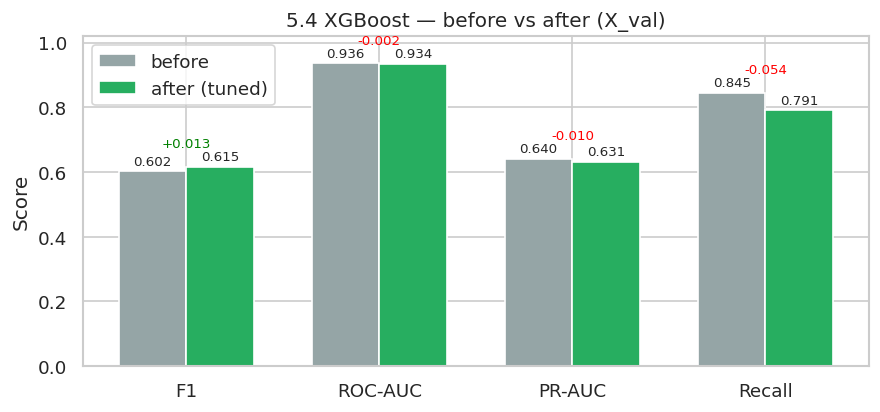


Luu: tuned_54_xgb (best_params={'clf__subsample': 0.7, 'clf__scale_pos_weight': 9.81, 'clf__n_estimators': 200, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8})

[info] optuna chua cai -> bo qua Optuna (pip install optuna)

=== Tong hop tuned_results (sap xep theo F1_after tren X_val) ===


,model,status,cv_best_F1,F1_before,F1_after,Delta_F1,best_params
0,RandomForest,tuned,0.6160,0.4609,0.6225,0.1616,"{'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 4, 'clf__max_features': None, 'clf__max_depth': 30, 'clf__class_weight': 'balanced_subsample'}"
1,XGBoost,tuned,0.6186,0.6023,0.6154,0.0131,"{'clf__subsample': 0.7, 'clf__scale_pos_weight': 9.81, 'clf__n_estimators': 200, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8}"
2,LogisticRegression,tuned,0.5513,0.5524,0.5569,0.0045,"{'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__class_weight': 'balanced', 'clf__C': 1}"
3,AdaBoost,tuned,0.4643,0.4505,0.4831,0.0326,"{'clf__n_estimators': 300, 'clf__learning_rate': 1.2}"



Luu: tuned_51_lr, tuned_52_rf, tuned_53_ada, tuned_54_xgb, compare_5*_df, tuned_results
X_test van chua dung — giu cho Buoc 6c.


In [11]:
# ============================================================
# 5.4 XGBoost — tim tham so toi uu
# - Tu bo qua neu chua pip install xgboost (khong crash)
# - scale_pos_weight tinh tu y_train (~7.55) giu co dinh hoac tune nhe
# ============================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[5.4] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}%")

try:
    from xgboost import XGBClassifier
    _has_xgb = True
except ImportError:
    _has_xgb = False
    print("[warn] xgboost chua cai (pip install xgboost) -> bo qua 5.4")
    tuned_54_xgb = None
    compare_54_df = pd.DataFrame()

if _has_xgb:
    n_pos=int((y_train==1).sum()); n_neg=int((y_train==0).sum()); spw = round(float(n_neg/max(n_pos,1)),2)
    print(f"  y 0/1={n_neg}/{n_pos} -> scale_pos_weight={spw}")
    try:
        _probe=XGBClassifier(n_estimators=10); _has_ule="use_label_encoder" in _probe.get_params()
    except Exception: _has_ule=False

    # before
    _kw_before=dict(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=spw, random_state=42, n_jobs=-1, eval_metric="logloss")
    if _has_ule: _kw_before["use_label_encoder"]=False
    pipe_before_xgb=Pipeline([('pre', clone(preprocessor)), ('clf', XGBClassifier(**_kw_before))])
    pipe_before_xgb.fit(X_train, y_train)
    y_pred_b=pipe_before_xgb.predict(X_val); y_proba_b=pipe_before_xgb.predict_proba(X_val)[:,1]
    before_xgb={"F1": f1_score(y_val, y_pred_b, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_b), "PR-AUC": average_precision_score(y_val, y_proba_b), "Recall": recall_score(y_val, y_pred_b, zero_division=0)}
    print(f"  before (default) | F1={before_xgb['F1']:.4f} ROC={before_xgb['ROC-AUC']:.4f} PR={before_xgb['PR-AUC']:.4f} Rec={before_xgb['Recall']:.4f}")

    # search
    pipe_xgb=Pipeline([('pre', clone(preprocessor)), ('clf', XGBClassifier(scale_pos_weight=spw, random_state=42, n_jobs=-1, eval_metric="logloss", **({"use_label_encoder": False} if _has_ule else {})))])
    param_dist_xgb={
        'clf__n_estimators': [100, 200, 300, 500],
        'clf__max_depth': [3, 4, 5, 6, 8, 10],
        'clf__learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1, 0.15],
        'clf__subsample': [0.7, 0.8, 0.9, 1.0],
        'clf__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
        'clf__scale_pos_weight': [spw, round(spw*0.7,2), round(spw*1.3,2)],
    }
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    search_xgb=RandomizedSearchCV(pipe_xgb, param_dist_xgb, n_iter=18, cv=cv, scoring='f1', n_jobs=-1, random_state=42, verbose=1, error_score='raise')
    t0=time.perf_counter()
    search_xgb.fit(X_train, y_train)
    print(f"  RandomizedSearchCV done in {time.perf_counter()-t0:.1f}s")
    print(f"  best F1 (CV)={search_xgb.best_score_:.4f} | best_params={search_xgb.best_params_}")

    pipe_after_xgb=search_xgb.best_estimator_
    y_pred_a=pipe_after_xgb.predict(X_val); y_proba_a=pipe_after_xgb.predict_proba(X_val)[:,1]
    after_xgb={"F1": f1_score(y_val, y_pred_a, zero_division=0), "ROC-AUC": roc_auc_score(y_val, y_proba_a), "PR-AUC": average_precision_score(y_val, y_proba_a), "Recall": recall_score(y_val, y_pred_a, zero_division=0)}
    print(f"  after  (tuned)  | F1={after_xgb['F1']:.4f} ROC={after_xgb['ROC-AUC']:.4f} PR={after_xgb['PR-AUC']:.4f} Rec={after_xgb['Recall']:.4f}")

    compare_54_df=pd.DataFrame([
        {"version": "before (default)", **before_xgb, "cv_best_F1": np.nan},
        {"version": "after (tuned)",    **after_xgb,  "cv_best_F1": search_xgb.best_score_},
    ])
    compare_54_df["Delta_F1"]=compare_54_df["F1"]-before_xgb["F1"]
    for col in ["ROC-AUC","PR-AUC","Recall"]:
        compare_54_df.loc[1, f"d_{col}"] = after_xgb[col]-before_xgb[col]
    print("\n=== 5.4 compare (X_val) ===")
    _display(compare_54_df.style.format({"F1":"{:.4f}","ROC-AUC":"{:.4f}","PR-AUC":"{:.4f}","Recall":"{:.4f}","cv_best_F1":"{:.4f}","Delta_F1":"{:.4f}","d_ROC-AUC":"{:.4f}","d_PR-AUC":"{:.4f}","d_Recall":"{:.4f}"}))

    fig, ax=plt.subplots(figsize=(7.5,3.6))
    metrics=["F1","ROC-AUC","PR-AUC","Recall"]
    x=np.arange(len(metrics)); b=[before_xgb[m] for m in metrics]; a=[after_xgb[m] for m in metrics]; w=0.35
    ax.bar(x-w/2, b, w, label="before", color="#95a5a6"); ax.bar(x+w/2, a, w, label="after (tuned)", color="#27ae60")
    ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0,1.02); ax.set_ylabel("Score"); ax.legend()
    ax.set_title("5.4 XGBoost — before vs after (X_val)")
    for i,(bv,av) in enumerate(zip(b,a)):
        ax.text(i-w/2, bv+0.02, f"{bv:.3f}", ha="center", fontsize=8)
        ax.text(i+w/2, av+0.02, f"{av:.3f}", ha="center", fontsize=8)
        d=av-bv; ax.text(i, max(bv,av)+0.06, f"{d:+.3f}", ha="center", fontsize=8, color="green" if d>=0 else "red")
    plt.tight_layout(); plt.show()

    tuned_54_xgb={"model": "XGBoost", "best_params": search_xgb.best_params_, "cv_best_F1": float(search_xgb.best_score_), "before": before_xgb, "after": after_xgb, "best_estimator": pipe_after_xgb, "search": search_xgb}
    print(f"\nLuu: tuned_54_xgb (best_params={search_xgb.best_params_})")

    try:
        import optuna
        from sklearn.model_selection import cross_val_score
        print("\n--- Optuna (25 trials, scoring=average_precision) ---")
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        def objective_xgb(trial):
            params=dict(
                n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                max_depth=trial.suggest_int("max_depth", 3, 10),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
                subsample=trial.suggest_float("subsample", 0.7, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.7, 1.0),
                scale_pos_weight=trial.suggest_float("scale_pos_weight", spw*0.6, spw*1.4),
                random_state=42, n_jobs=-1, eval_metric="logloss",
            )
            if _has_ule: params["use_label_encoder"]=False
            clf=XGBClassifier(**params)
            pipe=Pipeline([('pre', clone(preprocessor)), ('clf', clf)])
            return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1).mean()
        study_xgb=optuna.create_study(direction="maximize")
        study_xgb.optimize(objective_xgb, n_trials=25, show_progress_bar=True)
        print(f"  Optuna best AP={study_xgb.best_value:.4f} | params={study_xgb.best_params}")
        bp=study_xgb.best_params; bp.update({"random_state":42,"n_jobs":-1,"eval_metric":"logloss"})
        if _has_ule: bp["use_label_encoder"]=False
        pipe_opt=Pipeline([('pre', clone(preprocessor)), ('clf', XGBClassifier(**bp))])
        pipe_opt.fit(X_train, y_train)
        yp=pipe_opt.predict(X_val); ypr=pipe_opt.predict_proba(X_val)[:,1]
        opt_after={"F1": f1_score(y_val, yp, zero_division=0), "PR-AUC": average_precision_score(y_val, ypr), "ROC-AUC": roc_auc_score(y_val, ypr)}
        print(f"  Optuna on X_val | F1={opt_after['F1']:.4f} PR={opt_after['PR-AUC']:.4f} ROC={opt_after['ROC-AUC']:.4f}")
        tuned_54_xgb["optuna_best_params"]=bp; tuned_54_xgb["optuna_best_AP"]=float(study_xgb.best_value); tuned_54_xgb["optuna_val_metrics"]=opt_after
    except ImportError:
        print("\n[info] optuna chua cai -> bo qua Optuna (pip install optuna)")
    except Exception as e:
        print(f"\n[warn] Optuna loi: {e}")

# --- Tong hop tuned_results cho ca 4 model (de Buoc 6 chon BEST) ---
import pandas as pd
rows=[]
for _name, _var in [("LogisticRegression","tuned_51_lr"), ("RandomForest","tuned_52_rf"), ("AdaBoost","tuned_53_ada"), ("XGBoost","tuned_54_xgb")]:
    obj = globals().get(_var)
    if obj is None:
        rows.append({"model": _name, "status": "skip (thieu lib)", "cv_best_F1": None, "F1_before": None, "F1_after": None, "Delta_F1": None, "best_params": None})
    else:
        rows.append({"model": _name, "status": "tuned", "cv_best_F1": obj["cv_best_F1"], "F1_before": obj["before"]["F1"], "F1_after": obj["after"]["F1"], "Delta_F1": obj["after"]["F1"]-obj["before"]["F1"], "best_params": str(obj["best_params"])})
tuned_results = pd.DataFrame(rows).sort_values("F1_after", ascending=False, na_position="last").reset_index(drop=True)
print("\n=== Tong hop tuned_results (sap xep theo F1_after tren X_val) ===")
try: from IPython.display import display as _d; _d(tuned_results.style.format({"cv_best_F1":"{:.4f}","F1_before":"{:.4f}","F1_after":"{:.4f}","Delta_F1":"{:.4f}"}))
except Exception: print(tuned_results.to_string(index=False))
print("\nLuu: tuned_51_lr, tuned_52_rf, tuned_53_ada, tuned_54_xgb, compare_5*_df, tuned_results")
print("X_test van chua dung — giu cho Buoc 6c.")


## 6. Phan tich & Ket luan — chot 1 model ban giao (bao cao ca 4 model, 1 cell)

> **Muc tieu:** Chot **1 model duy nhat** de ban giao cho `src/models/train.py`, nhung **bao cao day du ca 4 model** trong 1 cell chung.

| Buoc nho | Noi dung | Ghi chu |
|----------|----------|---------|
| **6a** | **Chot model:** lay model co `F1_after` cao nhat sau tuning (Buoc 5) -> `BEST_NAME`, `BEST_PARAMS`, `BEST_ESTIMATOR` | Neu chua chay Buoc 5 thi fallback `results_all` (Buoc 4) |
| **6b** | **Feature Importance:** `feature_importances_ / |coef|` + `permutation_importance(scoring='f1')` tren `X_val` cho **ca 4 model** | Biet dac trung nao keo `y=yes` |
| **6c** | **Hold-out Test:** moi model `predict` **duy nhat 1 lan** tren `X_test` (khong tune them), so `F1 val vs test` de check overfit | `X_test` chua dung o Buoc 1-5 |
| **6d** | **Ban giao:** in khoi `BEST_MODEL = "..."` + `BEST_PARAMS = {...}` de copy thang sang `src/models/train.py` |  |

> **Output cuoi notebook:** `BEST_NAME` + `BEST_PARAMS` + bang `val vs test` cho ca 4 model + hinh importance/CM.


[6] X_train=(31647, 17) yes=11.70% | X_val=(6782, 17) yes=11.71% | X_test=(6782, 17) yes=11.69%

=== 6a. Chot model (F1_after cao nhat) ===
  LogisticRegression: tuned co — F1_after=0.5569 cv_best=0.5513 params={'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__class_weight': 'balanced', 'clf__C': 1}
  RandomForest: tuned co — F1_after=0.6225 cv_best=0.6160 params={'clf__n_estimators': 300, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 4, 'clf__max_features': None, 'clf__max_depth': 30, 'clf__class_weight': 'balanced_subsample'}
  AdaBoost: tuned co — F1_after=0.4831 cv_best=0.4643 params={'clf__n_estimators': 300, 'clf__learning_rate': 1.2}
  XGBoost: tuned co — F1_after=0.6154 cv_best=0.6186 params={'clf__subsample': 0.7, 'clf__scale_pos_weight': 9.81, 'clf__n_estimators': 200, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__colsample_bytree': 0.8}

  >>> BEST (tu tuned) = RandomForest | F1_val=0.6225 | params={'clf__n_estimators': 300, 'clf__min_samples_split': 

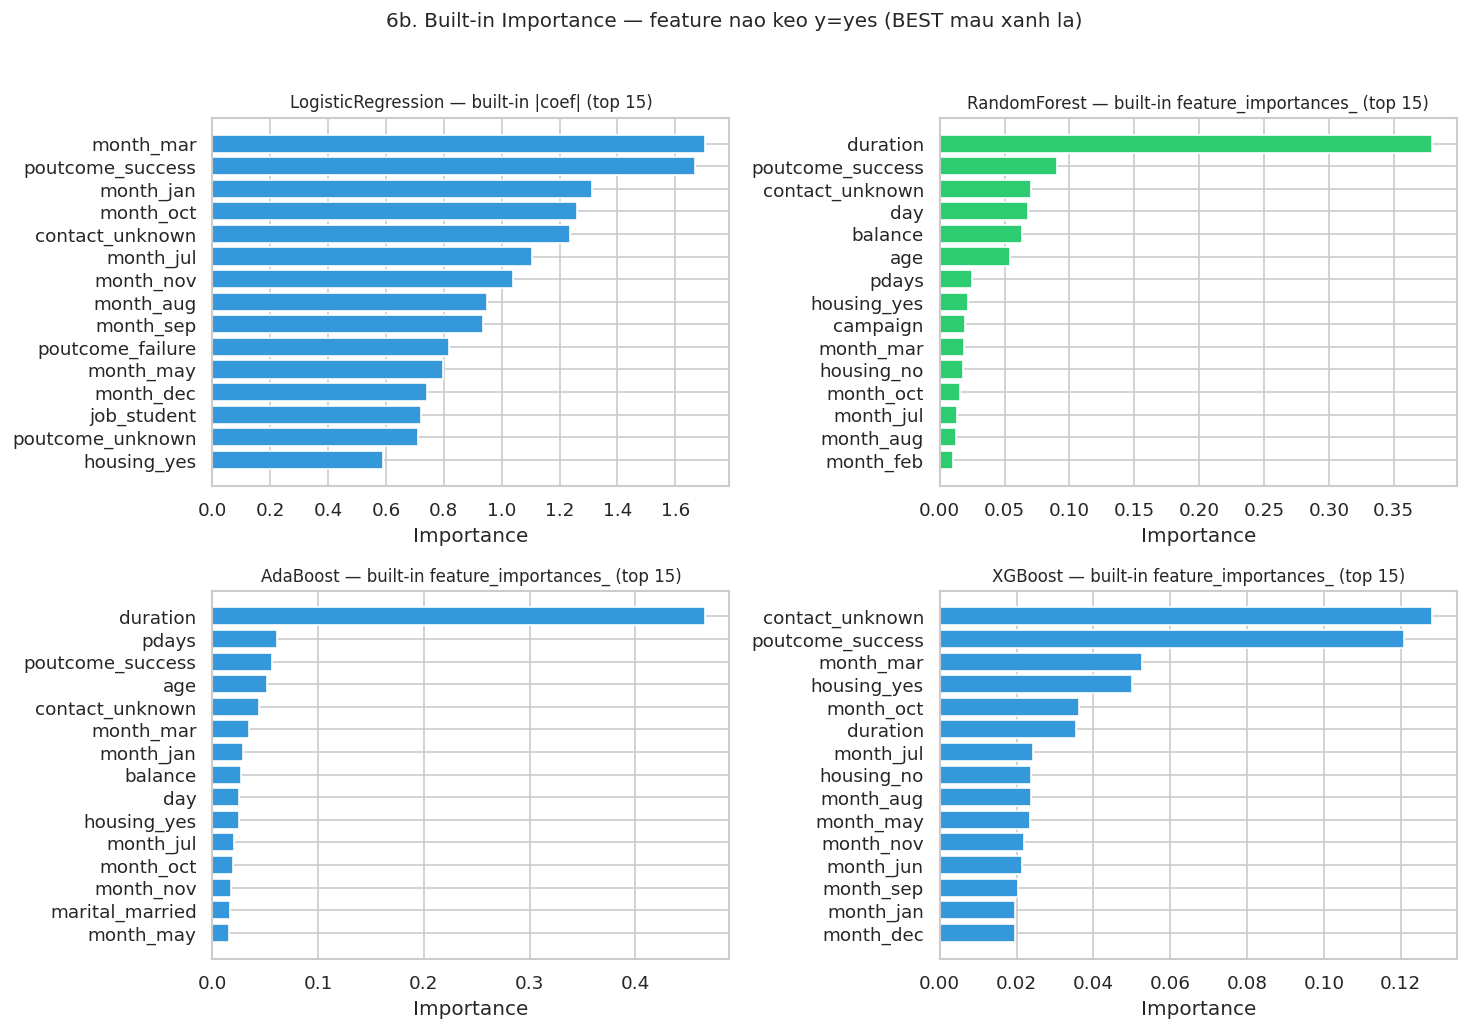


--- Built-in top 10 — RandomForest ---


,feature,importance,kind
0,duration,0.3797,feature_importances_
1,poutcome_success,0.0906,feature_importances_
2,contact_unknown,0.0706,feature_importances_
3,day,0.0682,feature_importances_
4,balance,0.0630,feature_importances_
5,age,0.0541,feature_importances_
6,pdays,0.0246,feature_importances_
7,housing_yes,0.0218,feature_importances_
8,campaign,0.0197,feature_importances_
9,month_mar,0.0188,feature_importances_


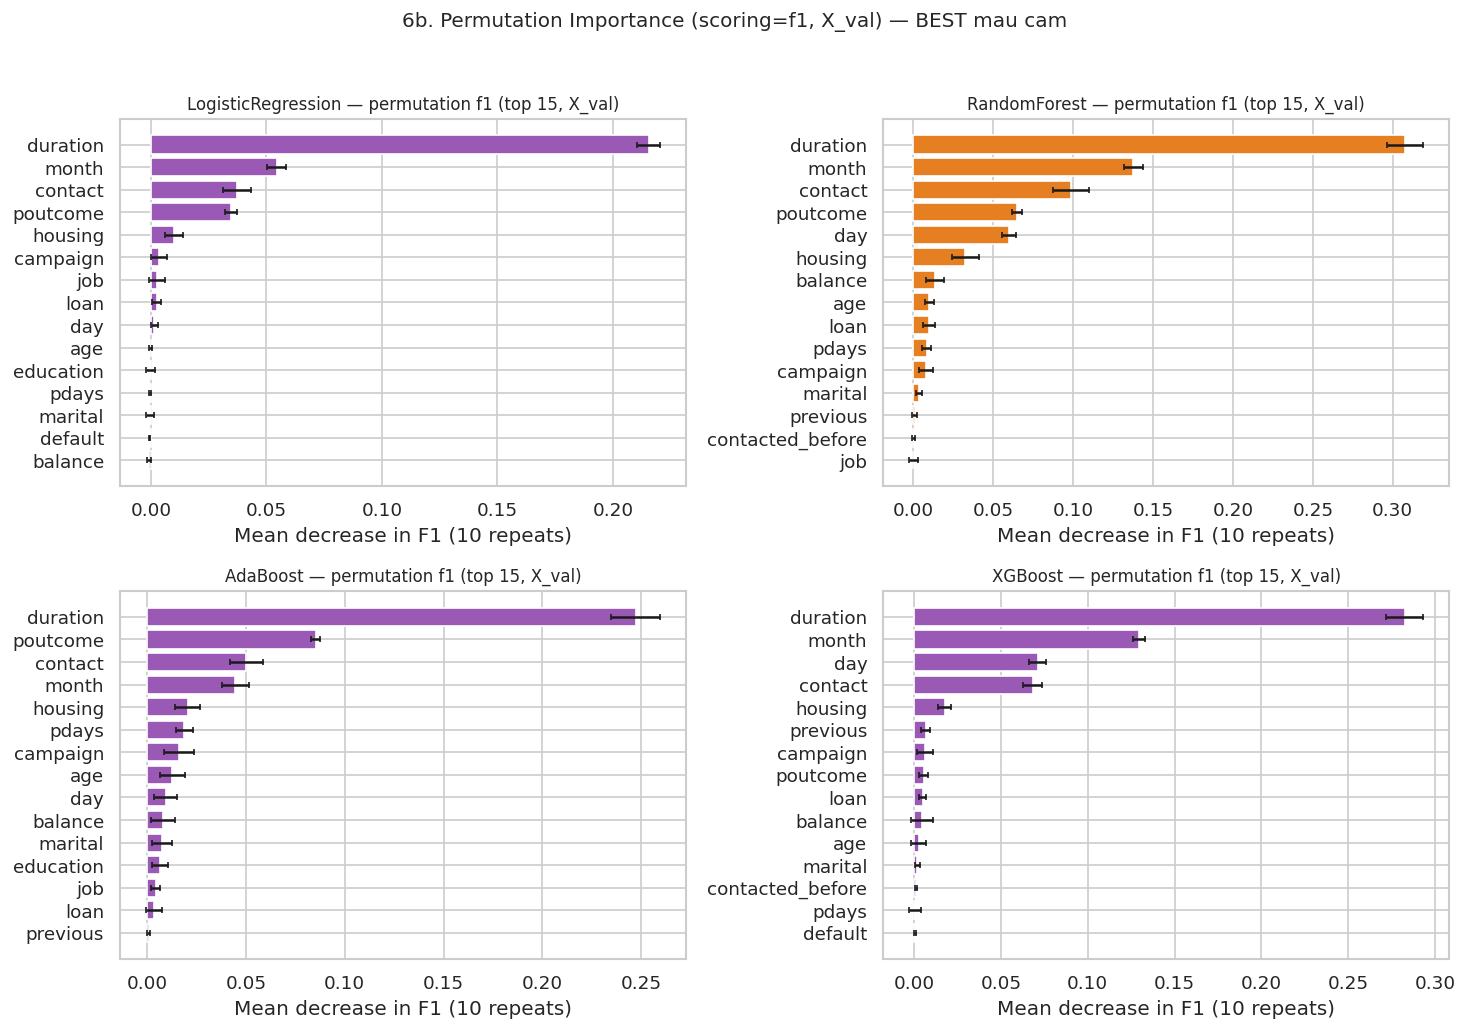


--- Permutation top 10 — RandomForest (X_val, f1) ---


,feature,importance_mean,importance_std
0,duration,0.3078,0.0113
1,month,0.1377,0.0061
2,contact,0.0987,0.0110
3,poutcome,0.0650,0.0030
4,day,0.0598,0.0044
5,housing,0.0326,0.0084
6,balance,0.0138,0.0056
7,age,0.0101,0.0029
8,loan,0.0100,0.0039
9,pdays,0.0086,0.0028



  Giao top10 built-in & permutation (RandomForest): age, balance, day, duration, pdays

=== 6c. Hold-out Test (X_test, khong tune them) ===
  LogisticRegression   | F1 val=0.5569 test=0.5462 Δ=-0.0107 | PR val=0.5566 test=0.5262 | CM test TN=5068 FP=921 FN=149 TP=644
  RandomForest         | F1 val=0.6225 test=0.6026 Δ=-0.0199 | PR val=0.6297 test=0.5847 | CM test TN=5502 FP=487 FN=241 TP=552
  AdaBoost             | F1 val=0.4831 test=0.4443 Δ=-0.0388 | PR val=0.5828 test=0.5438 | CM test TN=5805 FP=184 FN=514 TP=279
  XGBoost              | F1 val=0.6154 test=0.6090 Δ=-0.0064 | PR val=0.6306 test=0.5894 | CM test TN=5350 FP=639 FN=166 TP=627

=== 6c. Bang val vs test cho ca 4 model (sap xep theo F1_test) ===


,model,F1_val,F1_test,Delta_F1,ROC_val,ROC_test,PR_val,PR_test,Rec_val,Rec_test,TN,FP,FN,TP,is_best
0,XGBoost,0.6154,0.6090,-0.0064,0.9341,0.9246,0.6306,0.5894,0.7909,0.7907,5350,639,166,627,False
1,RandomForest ★ BEST,0.6225,0.6026,-0.0199,0.9341,0.9213,0.6297,0.5847,0.7040,0.6961,5502,487,241,552,True
2,LogisticRegression,0.5569,0.5462,-0.0107,0.9101,0.9047,0.5566,0.5262,0.8010,0.8121,5068,921,149,644,False
3,AdaBoost,0.4831,0.4443,-0.0388,0.9175,0.9047,0.5828,0.5438,0.3866,0.3518,5805,184,514,279,False


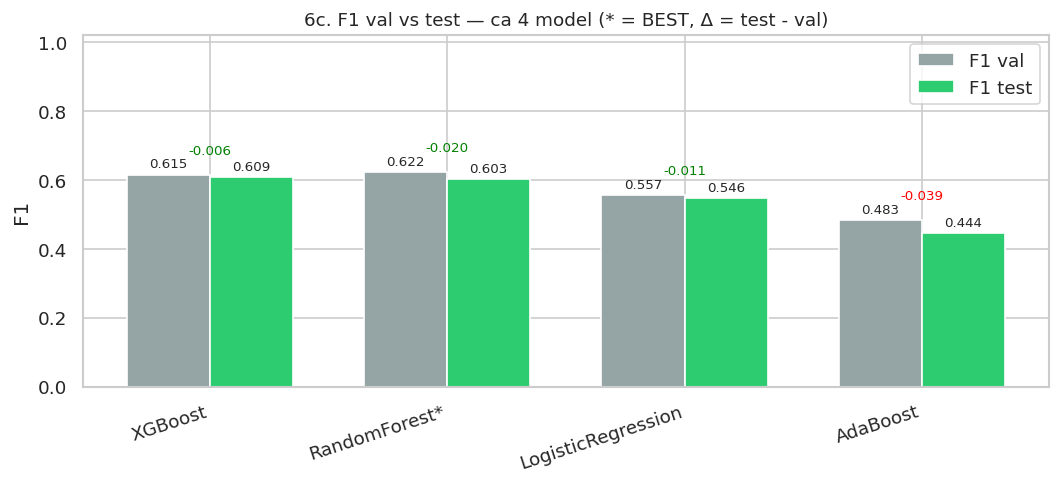

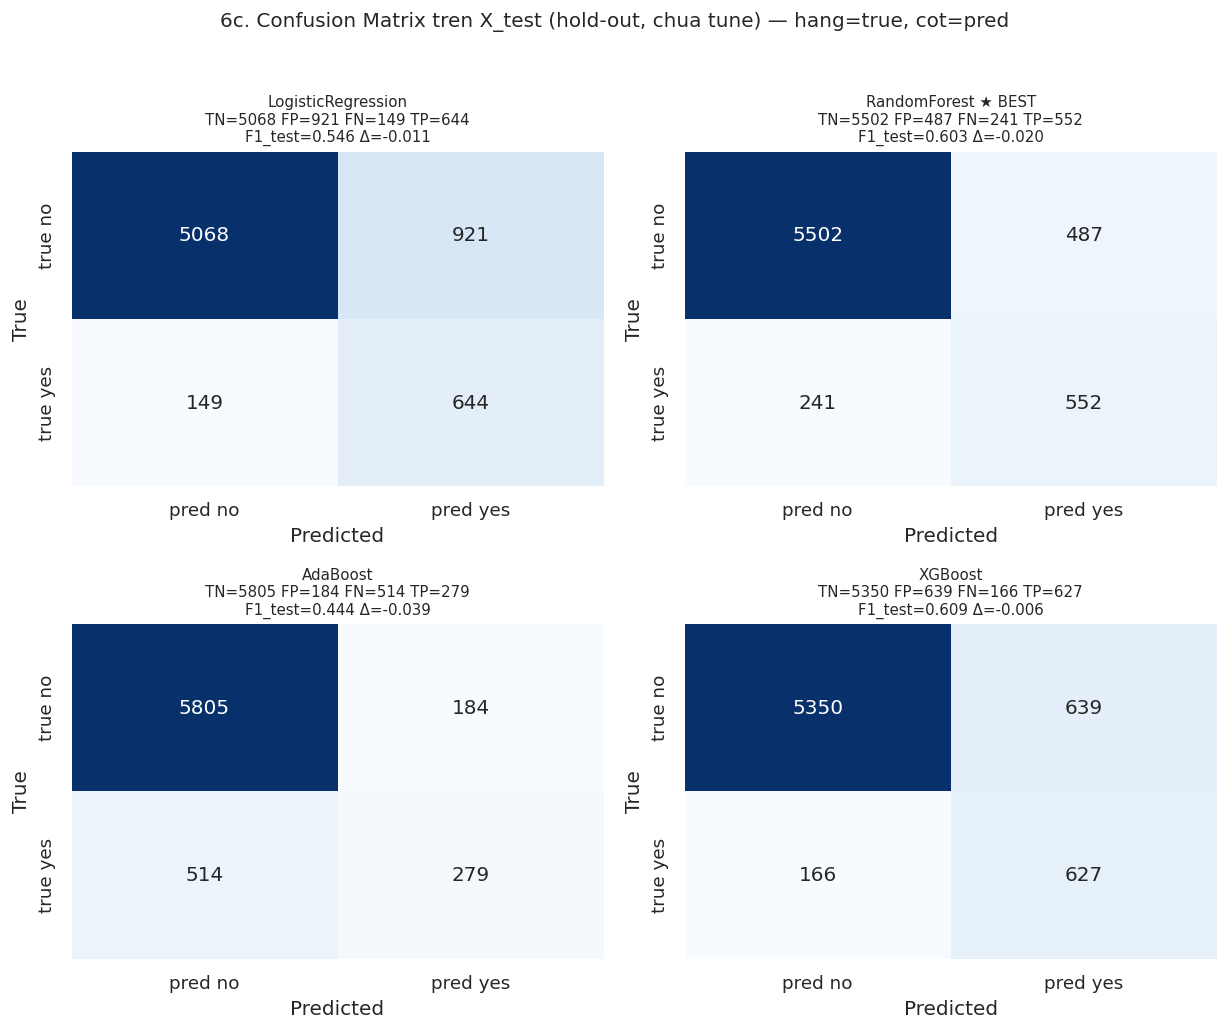


--- classification_report BEST=RandomForest tren X_test ---
              precision    recall  f1-score   support

      no (0)     0.9580    0.9187    0.9379      5989
     yes (1)     0.5313    0.6961    0.6026       793

    accuracy                         0.8927      6782
   macro avg     0.7447    0.8074    0.7703      6782
weighted avg     0.9081    0.8927    0.8987      6782

  [on] BEST RandomForest F1 val=0.6225 ~ test=0.6026 (Δ=-0.0199) — khong overfit dang ke

=== 6d. Ban giao cho src/models/train.py ===
  BEST_NAME   = "RandomForest"   # tuned (Buoc 5, F1_after tren X_val)
  BEST_CLASS  = RandomForestClassifier
  BEST_PARAMS = {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 30, 'class_weight': 'balanced_subsample'}
  F1_val=0.6225  F1_test=0.6026  PR_test=0.5847  ROC_test=0.9213

# --- Copy khoi duoi vao src/models/train.py ---
BEST_MODEL = "RandomForest"
BEST_PARAMS = {'n_estimators': 300, 'min_samples_split': 10, 

In [12]:
# ============================================================
# 6. Phan tich & Ket luan — 1 cell cho ca 4 model
# 6a chot BEST | 6b importance (|coef|/importances + permutation) | 6c hold-out test | 6d ban giao
# ============================================================
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score, roc_auc_score, average_precision_score, recall_score,
    confusion_matrix, classification_report
)
from sklearn.inspection import permutation_importance
try:
    from IPython.display import display as _display
except ImportError:
    _display = print

assert 'X_train' in globals() and 'y_train' in globals(), "Chua co X_train/y_train — chay Buoc 1"
assert 'X_val' in globals() and 'y_val' in globals(), "Chua co X_val/y_val — chay Buoc 1"
assert 'X_test' in globals() and 'y_test' in globals(), "Chua co X_test/y_test — chay Buoc 1"
assert 'preprocessor' in globals(), "Chua co preprocessor — chay Buoc 1"
print(f"[6] X_train={X_train.shape} yes={y_train.mean()*100:.2f}% | X_val={X_val.shape} yes={y_val.mean()*100:.2f}% | X_test={X_test.shape} yes={y_test.mean()*100:.2f}%")

# ------------------------------------------------------------
# 6a. Chot BEST_NAME / BEST_PARAMS / BEST_ESTIMATOR
# ------------------------------------------------------------
print("\n=== 6a. Chot model (F1_after cao nhat) ===")
candidates = {}
for _var, _label in [("tuned_51_lr","LogisticRegression"), ("tuned_52_rf","RandomForest"), ("tuned_53_ada","AdaBoost"), ("tuned_54_xgb","XGBoost")]:
    obj = globals().get(_var)
    if obj is not None and isinstance(obj, dict) and "best_estimator" in obj:
        candidates[_label] = obj
        print(f"  {_label}: tuned co — F1_after={obj['after']['F1']:.4f} cv_best={obj['cv_best_F1']:.4f} params={obj['best_params']}")
    else:
        print(f"  {_label}: chua co tuned ({_var} khong ton tai hoac skip) — se bo qua o 6a, nhung van bao cao o 6c neu co pipe_store/results_all")

if candidates:
    _best_label = max(candidates, key=lambda k: candidates[k]["after"]["F1"])
    _best_obj = candidates[_best_label]
    BEST_NAME = _best_label
    BEST_PARAMS = _best_obj["best_params"]
    BEST_ESTIMATOR = _best_obj["best_estimator"]
    BEST_F1_VAL = _best_obj["after"]["F1"]
    BEST_SOURCE = "tuned (Buoc 5, F1_after tren X_val)"
    print(f"\n  >>> BEST (tu tuned) = {BEST_NAME} | F1_val={BEST_F1_VAL:.4f} | params={BEST_PARAMS}")
else:
    if 'results_all' in globals() and 'pipe_store' in globals() and len(globals()['pipe_store'])>0:
        ra = globals()['results_all']
        ps = globals()['pipe_store']
        _best_label = ra.iloc[0]["model"]
        _short = _best_label.split("(")[0].strip()
        BEST_NAME = _short
        BEST_ESTIMATOR = ps[_best_label]
        try: BEST_PARAMS = {k.replace("clf__",""): v for k,v in BEST_ESTIMATOR.named_steps["clf"].get_params().items() if not k.startswith("pre")}
        except Exception: BEST_PARAMS = BEST_ESTIMATOR.named_steps["clf"].get_params()
        BEST_F1_VAL = float(ra.iloc[0]["F1"])
        BEST_SOURCE = "results_all (Buoc 4, chua tune)"
        print(f"\n  >>> BEST (fallback Buoc 4) = {BEST_NAME} | F1_val={BEST_F1_VAL:.4f} | nguyen model: {_best_label}")
        candidates = {_short: {"best_estimator": BEST_ESTIMATOR, "after": {"F1": BEST_F1_VAL}, "best_params": BEST_PARAMS, "cv_best_F1": np.nan}}
    else:
        raise RuntimeError("Khong co tuned_* (Buoc 5) cung khong co results_all/pipe_store (Buoc 4) — chay Buoc 4 hoac 5 truoc")

all_estimators = {}
for lbl, obj in candidates.items():
    all_estimators[lbl] = obj["best_estimator"]
if 'pipe_store' in globals():
    for full_name, pipe in globals()['pipe_store'].items():
        short = full_name.split("(")[0].strip()
        if short not in all_estimators:
            all_estimators[short] = pipe
print(f"  Tong so estimator se bao cao o 6b/6c: {list(all_estimators.keys())} (BEST={BEST_NAME})")

# ------------------------------------------------------------
# 6b. Feature Importance cho ca 4 model
# ------------------------------------------------------------
print("\n=== 6b. Feature Importance (X_val, scoring=f1) ===")
def _get_feature_names(pipe):
    try:
        pre = pipe.named_steps['pre']
        names = pre.get_feature_names_out()
        return list(names)
    except Exception:
        try: return list(num_cols) + list(cat_cols)
        except Exception: return [f"f{i}" for i in range(pipe.named_steps['clf'].n_features_in_)]

importance_builtin = {}
importance_perm = {}
for label, pipe in all_estimators.items():
    clf = pipe.named_steps['clf']
    feat_names = _get_feature_names(pipe)
    imp = None; kind = None
    if hasattr(clf, "feature_importances_"):
        imp = np.asarray(clf.feature_importances_, dtype=float); kind = "feature_importances_"
    elif hasattr(clf, "coef_"):
        coef = np.asarray(clf.coef_)
        if coef.ndim == 2: coef = coef[0]
        imp = np.abs(coef); kind = "|coef|"
    else:
        print(f"  {label}: khong co feature_importances_/coef_ — bo qua built-in")
    if imp is not None:
        if len(imp) != len(feat_names):
            feat_names = feat_names[:len(imp)] if len(feat_names) > len(imp) else feat_names + [f"f{i}" for i in range(len(imp)-len(feat_names))]
        df_imp = pd.DataFrame({"feature": feat_names, "importance": imp, "kind": kind})
        df_imp = df_imp.sort_values("importance", ascending=False).reset_index(drop=True)
        importance_builtin[label] = df_imp
        print(f"  {label} built-in ({kind}) top5: {', '.join(df_imp.head(5)['feature'].tolist())}")
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = permutation_importance(pipe, X_val, y_val, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
        df_perm = pd.DataFrame({"feature": X_val.columns.tolist(), "importance_mean": r.importances_mean, "importance_std": r.importances_std})
        df_perm = df_perm.sort_values("importance_mean", ascending=False).reset_index(drop=True)
        importance_perm[label] = df_perm
        print(f"  {label} permutation top5: {', '.join(df_perm.head(5)['feature'].tolist())}")
    except Exception as e:
        print(f"  {label} permutation loi: {e}")

if importance_builtin:
    n = len(importance_builtin)
    ncols = 2 if n > 1 else 1
    nrows = (n + ncols - 1)//ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2*ncols, 4.2*nrows), squeeze=False)
    axes = axes.flatten()
    for idx, (label, df_imp) in enumerate(importance_builtin.items()):
        ax = axes[idx]
        top = df_imp.head(15).iloc[::-1]
        kind = top["kind"].iloc[0]
        ax.barh(top["feature"], top["importance"], color="#2ecc71" if label==BEST_NAME else "#3498db")
        ax.set_title(f"{label} — built-in {kind} (top 15)", fontsize=10)
        ax.set_xlabel("Importance")
    for j in range(len(importance_builtin), len(axes)): fig.delaxes(axes[j])
    fig.suptitle("6b. Built-in Importance — feature nao keo y=yes (BEST mau xanh la)", fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()
    if BEST_NAME in importance_builtin:
        print(f"\n--- Built-in top 10 — {BEST_NAME} ---")
        _display(importance_builtin[BEST_NAME].head(10).style.format({"importance":"{:.4f}"}))

if importance_perm:
    n = len(importance_perm)
    ncols = 2 if n > 1 else 1
    nrows = (n + ncols - 1)//ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2*ncols, 4.2*nrows), squeeze=False)
    axes = axes.flatten()
    for idx, (label, df_perm) in enumerate(importance_perm.items()):
        ax = axes[idx]
        top = df_perm.head(15).iloc[::-1]
        ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#e67e22" if label==BEST_NAME else "#9b59b6", capsize=2)
        ax.set_title(f"{label} — permutation f1 (top 15, X_val)", fontsize=10)
        ax.set_xlabel("Mean decrease in F1 (10 repeats)")
    for j in range(len(importance_perm), len(axes)): fig.delaxes(axes[j])
    fig.suptitle("6b. Permutation Importance (scoring=f1, X_val) — BEST mau cam", fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()
    if BEST_NAME in importance_perm:
        print(f"\n--- Permutation top 10 — {BEST_NAME} (X_val, f1) ---")
        _display(importance_perm[BEST_NAME].head(10).style.format({"importance_mean":"{:.4f}","importance_std":"{:.4f}"}))
    if BEST_NAME in importance_builtin and BEST_NAME in importance_perm:
        overlap = set(importance_builtin[BEST_NAME].head(10)["feature"]) & set(importance_perm[BEST_NAME].head(10)["feature"])
        print(f"\n  Giao top10 built-in & permutation ({BEST_NAME}): {', '.join(sorted(overlap)) if overlap else '(khong trung)'}")

# ------------------------------------------------------------
# 6c. Hold-out Test — predict duy nhat 1 lan tren X_test cho ca 4 model
# ------------------------------------------------------------
print("\n=== 6c. Hold-out Test (X_test, khong tune them) ===")
test_rows = []
cm_test_store = {}
for label, pipe in all_estimators.items():
    y_pred_test = pipe.predict(X_test)
    try: y_proba_test = pipe.predict_proba(X_test)[:,1]
    except Exception:
        try:
            sc = pipe.decision_function(X_test)
            y_proba_test = (sc - sc.min())/(sc.max()-sc.min()+1e-12)
        except Exception: y_proba_test = y_pred_test.astype(float)
    y_pred_val = pipe.predict(X_val)
    try: y_proba_val = pipe.predict_proba(X_val)[:,1]
    except Exception: y_proba_val = y_pred_val.astype(float)
    f1_val = f1_score(y_val, y_pred_val, zero_division=0)
    f1_test = f1_score(y_test, y_pred_test, zero_division=0)
    roc_val = roc_auc_score(y_val, y_proba_val); roc_test = roc_auc_score(y_test, y_proba_test)
    pr_val = average_precision_score(y_val, y_proba_val); pr_test = average_precision_score(y_test, y_proba_test)
    rec_val = recall_score(y_val, y_pred_val, zero_division=0); rec_test = recall_score(y_test, y_pred_test, zero_division=0)
    cm = confusion_matrix(y_test, y_pred_test)
    cm_test_store[label] = cm
    test_rows.append({
        "model": label + ("  ★ BEST" if label==BEST_NAME else ""),
        "F1_val": f1_val, "F1_test": f1_test, "Delta_F1": f1_test - f1_val,
        "ROC_val": roc_val, "ROC_test": roc_test,
        "PR_val": pr_val, "PR_test": pr_test,
        "Rec_val": rec_val, "Rec_test": rec_test,
        "TN": cm[0,0], "FP": cm[0,1], "FN": cm[1,0], "TP": cm[1,1],
        "is_best": label==BEST_NAME,
    })
    print(f"  {label:20s} | F1 val={f1_val:.4f} test={f1_test:.4f} Δ={f1_test-f1_val:+.4f} | PR val={pr_val:.4f} test={pr_test:.4f} | CM test TN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}")

test_report = pd.DataFrame(test_rows).sort_values("F1_test", ascending=False).reset_index(drop=True)
print("\n=== 6c. Bang val vs test cho ca 4 model (sap xep theo F1_test) ===")
_display(test_report.style.format({"F1_val":"{:.4f}","F1_test":"{:.4f}","Delta_F1":"{:.4f}","ROC_val":"{:.4f}","ROC_test":"{:.4f}","PR_val":"{:.4f}","PR_test":"{:.4f}","Rec_val":"{:.4f}","Rec_test":"{:.4f}"}).background_gradient(subset=["F1_test"], cmap="YlGn").apply(lambda s: ["font-weight: bold" if v else "" for v in test_report["is_best"]], axis=0))

fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [r["model"].replace("  ★ BEST","*") for _, r in test_report.iterrows()]
x = np.arange(len(labels)); w=0.35
ax.bar(x-w/2, test_report["F1_val"], w, label="F1 val", color="#95a5a6")
ax.bar(x+w/2, test_report["F1_test"], w, label="F1 test", color="#2ecc71")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=18, ha="right")
ax.set_ylim(0, 1.02); ax.set_ylabel("F1"); ax.legend()
ax.set_title("6c. F1 val vs test — ca 4 model (* = BEST, Δ = test - val)", fontsize=11)
for i, r in test_report.iterrows():
    ax.text(i-w/2, r["F1_val"]+0.02, f"{r['F1_val']:.3f}", ha="center", fontsize=8)
    ax.text(i+w/2, r["F1_test"]+0.02, f"{r['F1_test']:.3f}", ha="center", fontsize=8)
    c = "green" if r["Delta_F1"] >= -0.02 else "red"
    ax.text(i, max(r["F1_val"], r["F1_test"])+0.06, f"{r['Delta_F1']:+.3f}", ha="center", fontsize=8, color=c)
plt.tight_layout(); plt.show()

n = len(cm_test_store)
ncols = 2 if n>1 else 1
nrows = (n+ncols-1)//ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.2*nrows), squeeze=False)
axes = axes.flatten()
for idx, (label, cm) in enumerate(cm_test_store.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["pred no","pred yes"], yticklabels=["true no","true yes"])
    r = test_report[test_report["model"].str.contains(label)].iloc[0]
    star = " ★ BEST" if label==BEST_NAME else ""
    ax.set_title(f"{label}{star}\nTN={cm[0,0]} FP={cm[0,1]} FN={cm[1,0]} TP={cm[1,1]}\nF1_test={r['F1_test']:.3f} Δ={r['Delta_F1']:+.3f}", fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for j in range(n, len(axes)): fig.delaxes(axes[j])
fig.suptitle("6c. Confusion Matrix tren X_test (hold-out, chua tune) — hang=true, cot=pred", fontsize=12, y=1.02)
plt.tight_layout(); plt.show()

print(f"\n--- classification_report BEST={BEST_NAME} tren X_test ---")
print(classification_report(y_test, all_estimators[BEST_NAME].predict(X_test), digits=4, target_names=["no (0)","yes (1)"], zero_division=0))
best_row = test_report[test_report["is_best"]].iloc[0]
if best_row["Delta_F1"] < -0.05:
    print(f"  [canh bao] BEST {BEST_NAME} giam F1 {best_row['Delta_F1']:+.4f} tu val sang test — co dau hieu overfit")
elif best_row["Delta_F1"] > 0.03:
    print(f"  [tot] BEST {BEST_NAME} tang F1 {best_row['Delta_F1']:+.4f} tren test — on dinh / tot hon val")
else:
    print(f"  [on] BEST {BEST_NAME} F1 val={best_row['F1_val']:.4f} ~ test={best_row['F1_test']:.4f} (Δ={best_row['Delta_F1']:+.4f}) — khong overfit dang ke")

# ------------------------------------------------------------
# 6d. Ban giao
# ------------------------------------------------------------
print("\n=== 6d. Ban giao cho src/models/train.py ===")
if any(k.startswith("clf__") for k in BEST_PARAMS.keys()):
    BEST_PARAMS_CLEAN = {k.replace("clf__",""): v for k,v in BEST_PARAMS.items()}
else:
    BEST_PARAMS_CLEAN = dict(BEST_PARAMS)
_class_map = {"LogisticRegression":"LogisticRegression","RandomForest":"RandomForestClassifier","AdaBoost":"AdaBoostClassifier","XGBoost":"XGBClassifier"}
_best_class = _class_map.get(BEST_NAME, BEST_NAME)
print(f'  BEST_NAME   = "{BEST_NAME}"   # {BEST_SOURCE}')
print(f"  BEST_CLASS  = {_best_class}")
print(f"  BEST_PARAMS = {BEST_PARAMS_CLEAN}")
print(f"  F1_val={best_row['F1_val']:.4f}  F1_test={best_row['F1_test']:.4f}  PR_test={best_row['PR_test']:.4f}  ROC_test={best_row['ROC_test']:.4f}")
if BEST_NAME=="XGBoost":
    n_pos=int((y_train==1).sum()); n_neg=int((y_train==0).sum())
    print(f"  scale_pos_weight ~ {n_neg/max(n_pos,1):.2f} (da nam trong BEST_PARAMS neu tune)")
print("\n# --- Copy khoi duoi vao src/models/train.py ---")
print(f'BEST_MODEL = "{BEST_NAME}"')
print(f"BEST_PARAMS = {repr(BEST_PARAMS_CLEAN)}")
print("# Dung:")
print("# from src.data.preprocessing_2 import build_preprocessor")
print("# from sklearn.pipeline import Pipeline")
print("# pre, _, _ = build_preprocessor()")
print(f"# clf = {_best_class}(**BEST_PARAMS)")
print("# pipe = Pipeline([('pre', pre), ('clf', clf)])")
print("# pipe.fit(X_train, y_train)")
print("\nLuu bien cuoi notebook: BEST_NAME, BEST_PARAMS, BEST_PARAMS_CLEAN, BEST_ESTIMATOR, all_estimators, test_report, importance_builtin, importance_perm")
print("Xong Buoc 6 — san sang ban giao.")
